# **TRANSPORTATION CONVENIENCE ACROSS U.S. CITIES**

# **Team Details**
**Team Number:** *3*
<br>
**Team Name:** Thomas
<br>
**Team Members:** *Ryan, Jingyu, Chenxi, Tobey*
<br>
**Project Manager:** *Tobey*

# **Motivation**
Students and recent graduates relocating for university or employment rely heavily on public transit to avoid auto ownership expenses. While mega-metropolises possess well-studied transit networks, transit convenience varies widely across lower and mid-tier population brackets. Analyzing 2020–2023 multi-year panel data across public transit, demographic, and economic datasets quantifies how population growth impacts student mobility, giving car-free graduates an empirical decision tool for evaluating relocation destinations.

# **Business Problem Definition**
Students and recent graduates need convenient and accessible transportation when choosing where to live for school or work. However, it can be difficult to compare cities using multiple transportation factors at the same time.

Transit ridership, funding, and walkability shifted between 2020 and 2023 as cities recovered from the pandemic, and these changes differed across small (under 100K), medium (100K–450K), and big (450K+) cities. Such shifts are hard to compare without data-driven tools, which leaves a clear gap in mobility analytics for car-free students. This project uses 4 years of data (2020–2023) from Census population estimates, the National Transit Database (funding and ridership), and block-group walkability indexes, yielding 920 city-year observations across 230 cities.

Success Metrics:

* Develop a Transportation Convenience Score that combines transit usage, transportation funding, and walkability.
* Identify the highest- and lowest-scoring cities within each population tier.
* Determine whether population growth is associated with changes in transportation convenience from 2020–2023.
* Compare transportation convenience across small, medium, and large cities to identify which population tier performs best overall.
* Complete sufficient analysis to proceed in future actions using ML regression models

# **Data Source, Description and Data Dictionary**

This section describes all datasets used in this project and provides clear definitions of each variable, its data type, and its license. This helps ensure interpretability for readers without a transportation planning or GIS background.

### Data Overview

This project combines six data files spanning three categories: population, transportation (funding and ridership), and walkability. All sources are joined at the city or block-group level and cover cities across all three population tiers: small (under 100,000), medium (100,000–450,000), and large (450,000+). The project's working analysis window is 2020–2023, the post-pandemic period; individual source files can span a wider range than this, as noted dataset by dataset below.

### Data Sizes
Data size (rows × columns | number of files | total size in MB/GB)
- Total: ~2,923,639 rows | 6 files | ~1,788.4 MB (1.79 GB) raw
Breakdown:
- City and Town Population: ~1,969 x 9, 145 KB
- NTD Funding Sources: 6,813 x 18, ~3 MB
- Raw Monthly Ridership Data: ~2,357 x 310, 14.5MB
- Social Data Commons Walkability Index (2017-2023): 2,662,926 x 7, 150.5MB
- EPA National Walkability Index: 220,653 x 28, 1500.3MB
- 2010 Census DP1 Places Shapefile: 29,514 x 198, 123MB

### 1. City and Town Population Data (population_2020.xlsx)

This dataset comes from the [U.S. Census Bureau's city and town population estimates, 2020s vintage](https://www.census.gov/data/tables/time-series/demo/popest/2020s-total-cities-and-towns.html). It provides annual population estimates for every incorporated place and census-designated place in the United States from 2020 through 2025, and is the dataset used to identify and track cities across the three population tiers studied in this project. Below is a data dictionary of each column within this dataset.
#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| City | City or town name, parsed and cleaned from the raw Census location field. | Public domain (U.S. Government Work) |
| State | U.S. state name, parsed and cleaned from the raw Census location field. | Public domain (U.S. Government Work) |
| Region | Census-style region (Northeast, Midwest, South, West) assigned from State. | Public domain (U.S. Government Work) |
| 2020–2025 | Estimated total population of the city for each given year. | Public domain (U.S. Government Work) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| City | object (string) |
| State | object (string) |
| Region | object (string) |
| 2020–2025 | Int64 (nullable integer) |

**Note for Non-Technical Readers:**
* A "population estimate" is the Census Bureau's best approximation of a city's population for a year between official censuses, not an exact count.
* U.S. Census Bureau statistical data is a work of the federal government and is not subject to copyright under 17 U.S.C. § 105, so it is in the public domain and free to use, though the Bureau asks that users not imply its endorsement.

### 2. Transit Funding Data (2024 TS1.1 Total Funding Time Series.xlsx)

This dataset comes from the Federal Transit Administration's [TS1.1 Total Funding Time Series](https://www.transit.dot.gov/ntd/data-product/ts11-total-funding-time-series-2), part of the National Transit Database (NTD). It reports total transit funding received by individual transit agencies each year from 2010 to 2024, broken out by federal, state, local, and other sources. For this project, agency-level funding was summed to the city level for the cities studied across the small, medium, and large population tiers, and expressed on a per-capita basis using the population data above. Below is a data dictionary of each column within this dataset.

#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| City | City where the reporting transit agency is headquartered, standardized to match the population dataset. | Public domain (U.S. Government Work) |
| State | Two-letter state abbreviation for the reporting agency. | Public domain (U.S. Government Work) |
| Year | Reporting year, 2010–2024. | Public domain (U.S. Government Work) |
| Funding | Total transit funding ($) reported by all agencies headquartered in that city for that year, summed across all sources. | Public domain (U.S. Government Work) |
| Funding per Capita | Funding divided by the city's population for that year; calculated in this project, not in the raw file. | Public domain (U.S. Government Work) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| City | object (string) |
| State | object (string) |
| Year | int64 |
| Funding | float64 |
| Funding per Capita | float64 |

**Note for Non-Technical Readers:**
* The raw file also includes agency identifiers and other metadata not used in this analysis.
* "Per capita" means the amount divided by population, so cities of different sizes can be compared fairly.

### 3. Raw Monthly Ridership Data (ridership.xlsx)

This dataset comes from the FTA's [NTD Monthly Module Raw Data Release](https://www.transit.dot.gov/ntd/data-product/monthly-module-raw-data-release), which reports monthly ridership, trip length, and cost data self-reported by every U.S. transit agency. This project uses the annual Unlinked Passenger Trips figure, aggregated to the city and urbanized-area (UZA) level, to measure how heavily transit is used relative to population. Below is a data dictionary of each column within this dataset.

#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| HQ City | City where the reporting transit agency is headquartered, standardized (uppercased, whitespace-cleaned). | Public domain (U.S. Government Work) |
| UACE CD | Census Urbanized Area Code identifying the urbanized area (UZA) a transit agency serves. | Public domain (U.S. Government Work) |
| UZA Name | Name of the urbanized area, e.g. "New York–Newark, NY–NJ–CT". | Public domain (U.S. Government Work) |
| UZA Population | Census population of the urbanized area. | Public domain (U.S. Government Work) |
| Unlinked Passenger Trips FY | Total annual unlinked passenger trips (each boarding counted separately, even on a single journey) for the fiscal year. | Public domain (U.S. Government Work) |
| Ridership Per Capita | Unlinked Passenger Trips FY divided by UZA Population; calculated in this project. | Public domain (U.S. Government Work) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| HQ City | object (string) |
| UACE CD | object (string) |
| UZA Name | object (string) |
| UZA Population | float64 |
| Unlinked Passenger Trips FY | float64 |
| Ridership Per Capita | float64 |

**Note for Non-Technical Readers:**
* Columns dropped before analysis (Legacy NTD ID, Last Closed Report Year, Last Closed FY End Month, Last Closed FY End Year) are administrative fields not needed for this study.

### 4. Social Data Commons Walkability Index, 2017–2023 (2017_2023_walkability_index.csv)

This dataset is Schroeder, A. (2026), [Social Data Commons: Walkability](https://doi.org/10.5281/zenodo.20545549) (v5.0.2), published on Zenodo by the University of Virginia. It provides an annual, block-group-level walkability score for the U.S. from 2017 to 2023, built from several underlying methods (observed, modeled, scaled, interpolated, or extrapolated). This project filters the file to block-group-level rows, matches each block group to a city using the spatial mapping built from the EPA and Census shapefiles below, and averages scores to the city-year level. Below is a data dictionary of each column within this dataset.

#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| geoid | 12-digit Census block group identifier. | CC BY 4.0 (Creative Commons Attribution 4.0 International) |
| region_type | Geographic level of the row, e.g. "block_group" or "tract"; this project keeps only block_group rows. | CC BY 4.0 (Creative Commons Attribution 4.0 International) |
| year | Year of the walkability observation, 2017–2023. | CC BY 4.0 (Creative Commons Attribution 4.0 International) |
| value | Walkability score for the block group in that year. | CC BY 4.0 (Creative Commons Attribution 4.0 International) |
| measure | Which metric the row reports (this project uses the walkability measure only). | CC BY 4.0 (Creative Commons Attribution 4.0 International) |
| data_method | How the value was produced: observed, modeled, scaled, interpolated, or extrapolated. | CC BY 4.0 (Creative Commons Attribution 4.0 International) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| geoid | object (string), zero-padded to 12 digits |
| region_type | object (string) |
| year | int64 |
| value | float64 |
| measure | object (string) |
| data_method | object (string) |

**Note for Non-Technical Readers:**
* A "block group" is a small Census geography, typically 600–3,000 people, smaller than a city or a census tract.

### 5. EPA National Walkability Index, 2010 vintage (Natl_WI.shp)

This dataset is the U.S. EPA's [National Walkability Index](https://www.epa.gov/smartgrowth/smart-location-mapping), derived from the Smart Location Database, with a walkability score for every Census block group in the country as of the 2010 vintage geography. In this project it is used both for its spatial boundaries, to geographically match each block group to a Census place (city), and as the earlier walkability benchmark compared against the 2017–2023 Social Data Commons scores above. Below is a data dictionary of the key columns used in this project (the full file contains 28 columns in total; additional intermediate variables are omitted here).

#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| GEOID10 | 12-digit Census block group identifier (2010 vintage), used to spatially join to Census places. | Public domain (U.S. Government Work) |
| StAbbr | Two-letter U.S. state postal abbreviation. | Public domain (U.S. Government Work) |
| Pop2010 | Total population of the block group, 2010 Census. | Public domain (U.S. Government Work) |
| NatWalkInd | National Walkability Index score (1–20, least to most walkable). | Public domain (U.S. Government Work) |
| D2A_Ranked, D2B_Ranked, D3B_Ranked, D4A_Ranked | Ranked (1–20) component scores behind NatWalkInd: employment/household mix, employment mix, intersection density, and transit proximity. | Public domain (U.S. Government Work) |
| geometry | Polygon boundary of the block group, used for the spatial join to city boundaries. | Public domain (U.S. Government Work) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| GEOID10 | object (string) |
| StAbbr | object (string) |
| Pop2010 | int64 |
| NatWalkInd | float64 |
| D2A_Ranked, D2B_Ranked, D3B_Ranked, D4A_Ranked | int64 |
| geometry | geometry (GeoPandas polygon) |

**Note for Non-Technical Readers:**
* The National Walkability Index score combines street intersection density, distance to transit, and land-use mix into a single 1–20 walkability rating per block group.
* This file uses 2010 Census block group boundaries, which is why it is spatially joined to the 2010 Census Place shapefile below rather than a newer boundary set.

### 6. 2010 Census DP1 Places Shapefile (Place_2010Census_DP1.zip)

This dataset is the U.S. Census Bureau's [2010 Census Summary File 1 Demographic Profile (DP1), Places](https://www.census.gov/geographies/mapping-files/2010/geo/tiger-data.html), a TIGER/Line shapefile giving the official 2010 boundary for every incorporated place and census-designated place, along with its full demographic profile. This project uses it only to define city boundaries, which the EPA walkability block groups are spatially joined to in order to assign each block group to a city. Below is a data dictionary of the key columns used in this project (the full file contains 198 demographic profile columns in total; only the geographic identifiers are used here).

#### Variable Descriptions

| Term | Definition | License |
|------|-------------|---------|
| NAMELSAD10 | Full place name including its legal/statistical descriptor, e.g. "Houston city". | Public domain (U.S. Government Work) |
| SFIPS | 2-digit state FIPS code for the place. | Public domain (U.S. Government Work) |
| GEOID10 | 7-digit Census place identifier (state FIPS + place code). | Public domain (U.S. Government Work) |
| geometry | Polygon boundary of the Census place, used for the spatial join with block groups. | Public domain (U.S. Government Work) |

#### Variable Data Types

| Term | Data Type |
|------|------------|
| NAMELSAD10 | object (string) |
| SFIPS | object (string) |
| GEOID10 | object (string) |
| geometry | geometry (GeoPandas polygon) |

**Note for Non-Technical Readers:**
* "DP1" (Demographic Profile 1) is the Census Bureau's standard 2010 summary of population, housing, race, and age for every place; this project only uses the file for its city boundaries, not its demographic columns.

# **Executive Summary**


This notebook looks at whether population growth changes how easy it is to get around without a car in U.S. cities from 2020 to 2023. We combined Census population estimates, FTA National Transit Database funding and ridership, and block-group walkability scores (UVA Social Data Commons 2017–2023) into one panel of 230 cities and 920 city-year rows. Each city got a Transportation Convenience Score from 0 to 100. The score weighs three things equally: transit funding per capita, transit ridership per capita, and walkability, each min-max scaled. Cities were grouped by 2020 population into Small (under 100K), Medium (100K–450K), and Big (450K+).

This notebook helps students and recent graduates who plan to live without a car compare transportation convenience across U.S. cities. We combined Census population estimates, FTA National Transit Database funding and ridership, and block-group walkability scores (UVA Social Data Commons 2017–2023) into one panel of 230 cities and 920 city-year rows from 2020 to 2023. Each city got a Transportation Convenience Score from 0 to 100. The score weighs three things equally: transit funding per capita, transit ridership per capita, and walkability, each min-max scaled. Cities were grouped by 2020 population into Small (under 100K), Medium (100K–450K), and Big (450K+) so they could be compared within and across tiers.

Big cities perform best overall. They have the highest median and average scores, the strongest post-pandemic ridership recovery (~58%), and they kept improving through 2023. Boston, Washington, Seattle, and San Francisco rank near the top. However, a big city is not the only good option. 22 small and medium cities match or beat the big-city average, led by Olympia, Miami, Salt Lake City, Pittsburgh, and Minneapolis. Region also matters: the Northeast leads in every tier, while small Southern cities score lowest. Walkability is the component most closely tied to the overall score, and the lowest-ranked cities have very little transit funding or ridership. Population growth from 2020 to 2023 had almost no link to changes in convenience, so a growing city is not automatically easier to live in without a car. For car-free movers, the most useful approach is to compare specific cities by score and by each of its three parts, not by size or growth alone.

1. **2020 City Size Distribution by Region** Counts Big, Medium, and Small cities in each Census region. → Medium cities are the most common tier in most regions, small cities lead in the Northeast, and big cities are scarce everywhere.
2. **Walkability vs Transit Use (Top 15 Cities)** Plots walkability against transit trips per capita. → Strong positive link. New York and San Francisco lead with 300+ trips per person, while Phoenix, Austin, Dallas, and Jacksonville stay under 50.
3. **Post-Pandemic Ridership Recovery by Tier** Compares ridership change from 2020 to 2023. → All tiers recovered. Big cities grew most (\~58%), followed by small (\~53%) and medium (\~40%).
4. **Transit Funding vs Population by Tier** Plots total funding against population within each tier. → Funding tracks population closely in big cities, loosely in medium cities, and barely at all in small cities, which mostly stay under $50M.
5. **Population Growth vs Walkability Change** Plots 2020–2023 growth against walkability change by tier. → Near-zero relationship for big and medium cities. Small cities show the only visible upward trend.
6. **Ridership per Funding Dollar by Tier** Divides transit trips by public funding. → Small cities get slightly more trips per dollar (\~0.083) than medium (\~0.079) and big (\~0.077), but the gap is small.
7. **Sub-Metric Contribution, Top 5 and Bottom 5 Cities** Breaks each city's score into funding, ridership, and walkability. → Boston and Washington are balanced, Seattle and San Francisco lean on walkability, and Olympia leans on funding. Bottom cities like Sherman and Evansville score almost entirely on walkability.
8. **Score Median and Spread by Tier** Compares median score and standard deviation. → Big cities have the highest median (\~26 vs \~23) and the widest spread. The tiers overlap a lot.
9. **Average Score by Year and Tier** Tracks the yearly average score from 2020 to 2023. → Big cities rose from ~31 to ~34, mostly after 2021. Medium (\~23) and small (\~22) stayed mostly flat.
10. **Population Growth vs Score Change** Four-quadrant scatter of all 230 cities. → r ≈ 0.03. Growth does not explain whether a city's convenience went up or down.
11. **Smaller Cities with Big-City Scores** Benchmarks small and medium cities against the big-city average (~32.1). → 11 small and 11 medium cities meet or beat it, led by Olympia (57.3), Miami (50.1), and Salt Lake City (48.5).
12. **Score by Region and Tier** Grouped bars of average score. → The Northeast leads every tier (big cities at 55.7). Small Southern cities score lowest (15.3). In the West, small cities slightly beat medium ones.
13. **Score Factor Correlation** Heatmap of the three components and the overall score. → Walkability is most tied to the score (0.85), then ridership (0.77) and funding (0.70). Part of this is built into the formula.
14. **Component Sensitivity to Population Growth** Correlates growth with change in each component. → All near zero (walkability 0.09, funding 0.02, ridership -0.08). No component responds much to growth.
15. **Regional Gaps for Small and Medium Cities** Compares score, walkability, funding, and ridership by region. → The South trails in both tiers (15.3 small, 18.9 medium). For small cities the biggest gap is low funding and ridership, while walkability holds up.


# **Summary of EDA**
The following are the summarized points for the work that we accomplished in the team assignment:
**1. Set the goal clearly.**

   We started by defining a plain-English objective: compare transportation convenience across U.S. cities to help students and recent graduates choose where to live for school or work. We turned that into a few simple questions, such as “Which cities offer the greatest transportation convenience?” and “How do small, medium, and large cities compare?” This kept the work focused on information useful for choosing a city.

2. Collect and lightly clean the data.
We brought together data from NTD and Walk Score focusing on 2020–2023. We standardized city and state names, made column names and year formats consistent, and checked for missing values. These steps helped us match records across sources and prepare the transportation indicators for comparison.

3. Put everything on the same timeline and make simple signals.
We aligned the datasets by city and year and organized transit usage, transportation funding, and walkability measures to support a Transportation Convenience Score. We also grouped cities into three population tiers: small (300,000–749,999), medium (750,000–1,499,999), and large (1.5 million or more). This structure allowed us to compare transportation conditions within and across population groups.

4. Answer questions with clear visuals, not jargon.
We created charts to compare transportation indicators across cities and show patterns over time. Each chart addressed a specific question, such as which cities had the highest transportation funding or how transportation convenience differed across small, medium, and large cities. These visuals made differences between cities easier to understand and supported comparisons across population tiers.

5. Translate pictures into takeaways and note limits.
We summarized what the visuals suggested about transportation conditions and how these comparisons could help students and recent graduates evaluate cities. We acknowledged that a single score simplifies several aspects of transportation convenience and may not reflect everyone's travel needs. Finally, we documented our sources and cleaning steps so the process would be transparent and repeatable, providing a foundation for future analysis.

# **Importing Libraries**

In [ ]:
import numpy as np
import pandas as pd
import csv
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import geopandas as gpd
import re

## **Block Summary**

We are importing some basic libraries which will come in handy while working on the entire project.

1. numpy --> Used for numerical computing, arrays, linear algebra, and mathematical operations.
2. pandas --> Used for working with structured data (tables, DataFrames, Series), data cleaning, and analysis.
3. geopandas --> Used for working with geospatial data (shapefiles, geometries) and performing spatial joins between block groups and city boundaries.
4. matplotlib.pyplot --> A plotting library for creating charts and visualizations.
5. matplotlib.ticker --> A custom axis tick mark location and label formatting library
6. seaborn --> Built on matplotlib, it provides easier and more attractive statistical plots.
7. re --> The built-in Python regular expressions module, used for pattern matching and string cleaning of city names.
8. google.colab.drive --> Used to mount Google Drive so the project's data files can be read directly from the shared Team Project folder.

# **Importing Files**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
pop_data = pd.read_excel('/content/drive/MyDrive/Team Project/population_2020.xlsx')
fund_data = pd.read_excel("/content/drive/MyDrive/Team Project/2024 TS1.1 Total Funding Time Series.xlsx",sheet_name="Total")
ride_data = pd.read_excel("/content/drive/MyDrive/Team Project/ridership.xlsx", sheet_name="Master")
upt_data = pd.read_excel(
    "/content/drive/MyDrive/Team Project/ridership.xlsx",
    sheet_name="Calendar Year UPT"
)
block_data = gpd.read_file('/content/drive/MyDrive/Team Project/Natl_WI_SHP/Natl_WI.shp')
city_data = gpd.read_file('https://www2.census.gov/geo/tiger/TIGER2010DP1/Place_2010Census_DP1.zip')
walkability_data = pd.read_csv("/content/drive/MyDrive/Team Project/2017_2023_walkability_index.csv")



## **Block Summary**

We are reading all the raw dataset files in the coding environment

*pop_data* ==> population_2020.xlsx
<br>
*fund_data* ==> 2024 TS1.1 Total Funding Time Series.xlsx
<br>
*ride_data* ==> ridership.xlsx, "Master" sheet
<br>
*upt_data* ==> ridership.xlsx, "Calendar Year UPT" sheet
<br>
*block_data* ==> Natl_WI_SHP/Natl_WI.shp
<br>
*city_data* ==> https://www2.census.gov/geo/tiger/TIGER2010DP1/Place_2010Census_DP1.zip

# **Data Sets**

## **pop_data Block Summary**

The code below gives the information + meta data about *mainData*

1. *pop_data .head()* ==> gives the first 10 rows of the Dataframe
2. *pop_data.info()* ==> gives the detailed information on each column of the Dataframe
3. *pop_data.describe()* ==> generates a statistical summary of the numerical columns of the Dataframe

In [ ]:
# Display the first 10 rows
print(pop_data.head(10))

# Display information about columns and data types
print(pop_data.info())

# Display a statistical summary of numerical columns
print(pop_data.describe())

  table with row headers in column B and column headers in rows 3 through 4 (leading dots indicate sub-parts)  \
0  Annual Estimates of the Resident Population fo...                                                            
1                                               Rank                                                            
2                                                NaN                                                            
3                                               1444                                                            
4                                                221                                                            
5                                               1735                                                            
6                                               1154                                                            
7                                               1075                                            

## **fund_data  Block Summary**

The code below gives the information + meta data about *fund_data*

1. *fund_data.head()* ==> gives the first 10 rows of the Dataframe
2. *fund_data.info()* ==> gives the detailed information on each column of the Dataframe
3. *fund_data.describe()* ==> generates a statistical summary of the numerical columns of the Dataframe

In [ ]:
# Display the first 10 rows
print(fund_data.head(10))

# Display information about columns and data types
print(fund_data.info())

# Display a statistical summary of numerical columns
print(fund_data.describe())

   Last Report Year  NTD ID Legacy NTD ID  \
0              2024     1.0             1   
1              2024     2.0             2   
2              2024     3.0             3   
3              2024     4.0          0T04   
4              2024     5.0             5   
5              2024     6.0             6   
6              2024     7.0             7   
7              2024     8.0             8   
8              2024     9.0          0T09   
9              2024    10.0          0T10   

                                         Agency Name Agency Status  \
0       King County (KCM) - Metro Transit Department        Active   
1                    Spokane Transit Authority (STA)        Active   
2  Pierce County Transportation Benefit Area Auth...        Active   
3  Confederated Tribes of the Colville Indian Res...        Active   
4                               City of Everett (ET)        Active   
5                                City of Yakima (YT)        Active   
6             

## **ride_data Block Summary**

The code below gives the information + meta data about *ride_data*

1. *ride_data.head()* ==> gives the first 10 rows of the Dataframe
2. *ride_data.info()* ==> gives the detailed information on each column of the Dataframe
3. *ride_data.describe()* ==> generates a statistical summary of the numerical columns of the Dataframe

In [ ]:
# Display the first 10 rows
print(ride_data.head(10))

# Display information about columns and data types
print(ride_data.info())

# Display a statistical summary of numerical columns
print(ride_data.describe())

   NTD ID Legacy NTD ID                     Agency Mode TOS 3 Mode  \
0       1          0001                King County   DR  PT    Bus   
1       1          0001                King County   DR  TX    Bus   
2       1          0001                King County   FB  DO  Ferry   
3       1          0001                King County   LR  DO   Rail   
4       1          0001                King County   MB  DO    Bus   
5       1          0001                King County   MB  PT    Bus   
6       1          0001                King County   SR  DO   Rail   
7       1          0001                King County   TB  DO    Bus   
8       1          0001                King County   VP  DO    Bus   
9       2          0002  Spokane Transit Authority   DR  DO    Bus   

  Mode/Type of Service Status  Reporter Type  \
0                      Active  Full Reporter   
1                      Active  Full Reporter   
2                      Active  Full Reporter   
3                    Inactive  Full R

## **upt_data Block Summary**

The code below gives the information + meta data about *upt_data*

1. *upt_data.head()* ==> gives the first 10 rows of the Dataframe


In [ ]:
# Display the first 10 rows
print(upt_data.head(10))

   NTD ID Legacy NTD ID                     Agency  \
0     1.0          0001                King County   
1     1.0          0001                King County   
2     1.0          0001                King County   
3     1.0          0001                King County   
4     1.0          0001                King County   
5     1.0          0001                King County   
6     1.0          0001                King County   
7     1.0          0001                King County   
8     1.0          0001                King County   
9     2.0          0002  Spokane Transit Authority   

  Mode/Type of Service Status  Reporter Type  UACE CD             UZA Name  \
0                      Active  Full Reporter  80389.0  Seattle--Tacoma, WA   
1                      Active  Full Reporter  80389.0  Seattle--Tacoma, WA   
2                      Active  Full Reporter  80389.0  Seattle--Tacoma, WA   
3                    Inactive  Full Reporter  80389.0  Seattle--Tacoma, WA   
4              

## **block_data Block Summary**

The code below gives the information + meta data about *block_data*

1. *block_data.head()* ==> gives the first 10 rows of the Dataframe
2. *block_data.info()* ==> gives the detailed information on each column of the Dataframe
3. *block_data.describe()* ==> generates a statistical summary of the numerical columns of the Dataframe

In [ ]:
# Display the first 10 rows
print(block_data.head(10))

# Display information about columns and data types
print(block_data.info())

# Display a statistical summary of numerical columns
print(block_data.describe())

        GEOID10  TRFIPS CFIPS SFIPS   CSA CSA_Name     CBSA       CBSA_Name  \
0  010059505002  950500   005    01  None     None  21640.0  Eufaula, AL-GA   
1  010059505001  950500   005    01  None     None  21640.0  Eufaula, AL-GA   
2  010059502001  950200   005    01  None     None  21640.0  Eufaula, AL-GA   
3  010059502002  950200   005    01  None     None  21640.0  Eufaula, AL-GA   
4  010059504002  950400   005    01  None     None  21640.0  Eufaula, AL-GA   
5  010059504003  950400   005    01  None     None  21640.0  Eufaula, AL-GA   
6  010059504001  950400   005    01  None     None  21640.0  Eufaula, AL-GA   
7  010059501002  950100   005    01  None     None  21640.0  Eufaula, AL-GA   
8  010059501001  950100   005    01  None     None  21640.0  Eufaula, AL-GA   
9  010059501003  950100   005    01  None     None  21640.0  Eufaula, AL-GA   

   COUNTHU10  TOTPOP10  ...       D3b      D4a  D2A_Ranked  D2B_Ranked  \
0      523.0    1119.0  ...  0.645676 -99999.0          

## **city_data Block Summary**

The code below gives the information + meta data about *city_data*

1. *city_data.head()* ==> gives the first 10 rows of the Dataframe
2. *city_data.info()* ==> gives the detailed information on each column of the Dataframe
3. *city_data.describe()* ==> generates a statistical summary of the numerical columns of the Dataframe

In [ ]:
# Display the first 10 rows
print(city_data.head(10))

# Display information about columns and data types
print(city_data.info())

# Display a statistical summary of numerical columns
print(city_data.describe())

   GEOID10         NAMELSAD10 CLASSFP10 MTFCC10 FUNCSTAT10      ALAND10  \
0  0180376          Webb town        C1   G4110          A   29526113.0   
1  0164152      Rehobeth town        C1   G4110          A   19635705.0   
2  0145904        Madrid town        C1   G4110          A    5025806.0   
3  0140072        Kinsey town        C1   G4110          A   31343903.0   
4  0144344    Louisville town        C1   G4110          A    7118467.0   
5  0124568       Eufaula city        C1   G4110          A  153817232.0   
6  0115640          Clio city        C1   G4110          A   26070288.0   
7  0115376       Clayton town        C1   G4110          A   17293294.0   
8  0107672  Blue Springs town        C1   G4110          A    7500883.0   
9  0103724     Bakerhill town        C1   G4110          A    7126271.0   

     AWATER10   INTPTLAT10    INTPTLON10  DP0010001  ...  DP0210001  \
0         0.0  +31.2576050  -085.2893794       1430  ...        544   
1     80600.0  +31.1245953  -085

# **Making Copies to Preserve the Original Datasets**

In [ ]:
pop_data_copy = pop_data.copy()
fund_data_copy = fund_data.copy()
ride_data_copy = ride_data.copy()
upt_data_copy = upt_data.copy()
block_data_copy = block_data.copy()
city_data_copy = city_data.copy()

# **Cleaning**

## **Cleaning pop_data**

### **Code Block 1**

*drop(index = range(0,3))* ==> removes the first 3 rows
<br>
*reset_index(drop=True)* ==> resets previous index, starting row index from 0
<br>
*.columns* ==> renames columns into useful labeling
<br>
*head()* ==> shows first 5 rows of updated data set



In [ ]:
# The first few rows contain the table headings, so we can start by removing those rows and renaming the columns
pop_data_copy = pop_data_copy.drop(index = range(0,3))
pop_data_copy = pop_data_copy.reset_index(drop = True)
cols = ['Rank','Location', 'Est', 2020, 2021, 2022, 2023, 2024, 2025]
pop_data_copy.columns = cols
pop_data_copy.head()

,Rank,Location,Est,2020,2021,2022,2023,2024,2025
0,1444,"Aberdeen city, South Dakota",28479,28424,28314.0,28177.0,28060.0,28008.0,27961.0
1,221,"Abilene city, Texas",124970,125194,125883.0,127376.0,129167.0,130136.0,131588.0
2,1735,"Acworth city, Georgia",22477,22439,22364.0,22380.0,22511.0,22643.0,22925.0
3,1154,"Addison village, Illinois",35702,35631,35384.0,35203.0,35353.0,35570.0,35758.0
4,1075,"Adelanto city, California",38038,38111,38157.0,37406.0,38134.0,38418.0,38798.0


### **Code Block 2**

Defines a function to tidy City and State names, removes irrelevant columns, and rearrange columns of the updated data set
<br>
Because we are only analyzing the convenience of years 2020 through 2023, years beyond 2023 are not relevant


In [ ]:
# We can then rearrange the location name into city and state, and remove irrelevant columns
def geolocation(df, location_col = 'Location'):
  df_clean = df.copy()

  # Extracts and standardizes all city names
  df_clean['City'] = df_clean[location_col].str.split(',').str.get(0).str.strip().str.title()

  # Extracts and standardizes all state names
  df_clean['State'] = df_clean[location_col].str.split(',').str.get(1).str.strip().str.title()

  # Drops non values
  df_clean = df_clean.dropna(subset = ['City','State'])
  df_clean = df_clean.drop(columns = ['Rank',location_col, 'Est', 2024, 2025])
  other_cols = [c for c in df_clean.columns if c not in ['City','State']]
  df_clean = df_clean[['City','State'] + other_cols]
  return df_clean

pop_data_copy = geolocation(pop_data_copy)
pop_data_copy.head()

,City,State,2020,2021,2022,2023
0,Aberdeen City,South Dakota,28424,28314.0,28177.0,28060.0
1,Abilene City,Texas,125194,125883.0,127376.0,129167.0
2,Acworth City,Georgia,22439,22364.0,22380.0,22511.0
3,Addison Village,Illinois,35631,35384.0,35203.0,35353.0
4,Adelanto City,California,38111,38157.0,37406.0,38134.0


### **Code Block 3**

Defines a function to standardize all City names using RegEx Python module to eliminate specific government naming conventions
<br>
*replace()* ==> replaces existing values with desired values
<br>
*strip()* ==> removes extra white space

In [ ]:
def clean_city_names(df):
    df_clean = df.copy()

    # Remove parentheticals
    df_clean['City'] = df_clean['City'].str.replace(
        r'\s*\([^)]*\)?', '', flags = re.IGNORECASE, regex = True
    )

    # Standardize all dash variants
    df_clean['City'] = df_clean['City'].str.replace(
        r'[\u2010-\u2015–—]', '-', regex = True
    )

    # Handle consolidated entities before removing legal designations
    consolidated_pattern = r'^\s*([A-Za-z\s\.]+?)[/-]\s*(?:Davidson|Fayette|Jefferson|Urban|County|Consolidated|Metropolitan|Metro|Town|Government|Borough).*'
    df_clean['City'] = df_clean['City'].str.replace(
        consolidated_pattern, r"\1", flags = re.IGNORECASE, regex = True
    )

    # Remove long consolidated/governmental legal descriptors at the end
    long_designations = r'\s+\b(Consolidated Government|Metropolitan Government|Metro Government|City And Borough|Urban County|Government|Municipality|Township|Town|Borough|Village|CDP)\b$'
    df_clean['City'] = df_clean['City'].str.replace(
        long_designations, '', flags = re.IGNORECASE, regex = True
    )

    # Remove Census legal 'city'/'town' designations ONLY when preceded by ' city' at the very end
    df_clean['City'] = df_clean['City'].str.replace(
        r'(?<=\bCity)\s+city$', '', flags = re.IGNORECASE, regex = True
    )
    df_clean["City"] = df_clean["City"].str.replace(
        r'(?<!\bOklahoma)(?<!\bKansas)(?<!\bSalt Lake)(?<!\bCarson)(?<!\bRapid)(?<!\bLake Havasu)(?<!\bIowa)(?<!\bRedwood)(?<!\bCulver)(?<!\bDodge)(?<!\bPanama)(?<!\bCathedral)\s+city$',
        '',
        flags = re.IGNORECASE,
        regex = True,
    )

    # Fix any double "City City" artifacts and strip white space
    df_clean['City'] = df_clean['City'].str.replace(
        r'\bCity\s+City\b', 'City', flags = re.IGNORECASE, regex = True
    )
    df_clean['City'] = df_clean['City'].str.strip()

    return df_clean
pop_data_copy = clean_city_names(pop_data_copy)

### **Code Block 4**

Defines a function to verify real state names within pop_data_copy for data validity, assign region name based on regions dictionary, and insert region column into pop_data_copy

*map(state_to_region)* ==> maps state to region
<br>
*dropna(subset=['Region']).reset_index(drop=True)* ==> drops any rows that do not have defined state and subsequent region name
<br>
*insert()* ==> inserts column into desired index

In [ ]:
# Now we can standardize states used and assign regions
def clean_and_add_region(df, state_col = 'State'):
    df_clean = df.copy()

    # Tidies and standardizes state names
    df_clean[state_col] = df_clean[state_col].astype(str).str.strip().str.title()
    regions = {
        'Northeast': ['Connecticut', 'Maine', 'Massachusetts', 'New Hampshire',
                      'Rhode Island', 'Vermont', 'New Jersey', 'New York', 'Pennsylvania'],
        'Midwest': ['Illinois', 'Indiana', 'Michigan', 'Ohio', 'Wisconsin',
                    'Iowa', 'Kansas', 'Minnesota', 'Missouri', 'Nebraska',
                    'North Dakota', 'South Dakota'],
        'South': ['Alabama', 'Arkansas', 'Delaware', 'District Of Columbia', 'Florida',
                  'Georgia', 'Kentucky', 'Louisiana', 'Maryland', 'Mississippi',
                  'North Carolina', 'Oklahoma', 'South Carolina', 'Tennessee',
                  'Texas', 'Virginia', 'West Virginia'],
        'West': ['Alaska', 'Arizona', 'California', 'Colorado', 'Hawaii',
                 'Idaho', 'Montana', 'Nevada', 'New Mexico', 'Oregon',
                 'Utah', 'Washington', 'Wyoming']
    }

    # Flatten nested dictionary into state to region keys
    state_to_region = {state: reg for reg, state_list in regions.items() for state in state_list}

    # Maps states to regions in a new Region column
    df_clean['Region'] = df_clean[state_col].map(state_to_region)

    # Remove rows with NaN values
    df_clean = df_clean.dropna(subset = ['Region']).reset_index(drop = True)

    # Rearrange Regions column
    region_col = df_clean.pop('Region')
    df_clean.insert(2, 'Region', region_col)

    return df_clean

pop_data_copy = clean_and_add_region(pop_data_copy)
pop_data_copy.head()

,City,State,Region,2020,2021,2022,2023
0,Aberdeen,South Dakota,Midwest,28424,28314.0,28177.0,28060.0
1,Abilene,Texas,South,125194,125883.0,127376.0,129167.0
2,Acworth,Georgia,South,22439,22364.0,22380.0,22511.0
3,Addison,Illinois,Midwest,35631,35384.0,35203.0,35353.0
4,Adelanto,California,West,38111,38157.0,37406.0,38134.0


### **Code Block 5**

Defines a function to identify and eliminate any 0 values

In [ ]:
def zeroes(df):
  df_clean = df.copy()
  zeroes = (df_clean == 0.0).any(axis = 1)
  df_clean = df_clean[~zeroes].reset_index(drop = True)
  return df_clean

pop_data_copy = zeroes(pop_data_copy)
display(zeroes(pop_data_copy.head()))
print('------------------------------------------------------------------')
print('Below are rows with 0 values:')
display(zeroes(pop_data_copy == 0))

,City,State,Region,2020,2021,2022,2023
0,Aberdeen,South Dakota,Midwest,28424,28314.0,28177.0,28060.0
1,Abilene,Texas,South,125194,125883.0,127376.0,129167.0
2,Acworth,Georgia,South,22439,22364.0,22380.0,22511.0
3,Addison,Illinois,Midwest,35631,35384.0,35203.0,35353.0
4,Adelanto,California,West,38111,38157.0,37406.0,38134.0


------------------------------------------------------------------
Below are rows with 0 values:


,City,State,Region,2020,2021,2022,2023


### **Code Block 6**

Defines a function to restructure data into tidy data, classify city size tiers, and standardize data types

*pd.melt()* ==> Reformats data into long form for rearrangement
<br>
*astype('int64')* ==> standardizes data type
<br>
*apply()* ==> applies a function across all passed values

In [ ]:
# Finally, we can group by city, state, region and year to fully tidy the pop_data data set and standardize data types into integers

def tidy(df):
    df_clean = df.copy()

    # Identify year and column data
    year_cols = df_clean.columns[3:]
    id_vars = [col for col in df_clean.columns if col not in year_cols]

    # Melt into long format
    df_melted = pd.melt(
        df_clean,
        id_vars = id_vars,
        value_vars = year_cols,
        var_name = 'Year',
        value_name = 'Population',
    )

    df_melted['Year'] = df_melted['Year'].astype(str)
    df_melted['Population'] = df_melted['Population'].astype('int64')

    # Create a unique MultiIndex lookup with city and state in 2020
    df_2020 = df_melted[df_melted['Year'] == '2020'].drop_duplicates(
        subset = ['City', 'State']
    )
    pop_2020_lookup = df_2020.set_index(['City', 'State'])['Population']

    # Define tier thresholds for small, medium, large
    def get_tier(pop):
        if pop >= 450000:
            return 'Big'
        elif pop >= 100000:
            return 'Medium'
        else:
            return 'Small'

    # Map baseline 2020 population back using MultiIndex (City, State)
    city_state_index = pd.MultiIndex.from_frame(df_melted[['City', 'State']])
    df_melted['Size Tier'] = (
        city_state_index.map(pop_2020_lookup).map(get_tier)
    )

    # Sort by city, state, and year
    df_melted = df_melted.sort_values(
        by=['City', 'State', 'Year']
    ).reset_index(drop = True)

    return df_melted

pop_data_copy = tidy(pop_data_copy)
pop_data_copy.head(10000)

,City,State,Region,Year,Population,Size Tier
0,Aberdeen,South Dakota,Midwest,2020,28424,Small
1,Aberdeen,South Dakota,Midwest,2021,28314,Small
2,Aberdeen,South Dakota,Midwest,2022,28177,Small
3,Aberdeen,South Dakota,Midwest,2023,28060,Small
4,Abilene,Texas,South,2020,125194,Medium
...,...,...,...,...,...,...
7831,Zion,Illinois,Midwest,2023,24449,Small
7832,Zionsville,Indiana,Midwest,2020,30786,Small
7833,Zionsville,Indiana,Midwest,2021,31646,Small
7834,Zionsville,Indiana,Midwest,2022,32031,Small


### **Code Block 7, 8, 9 & 10**

*info()* ==> shows basic information about the data including columns, types, and memory
<br>
*describe()* ==> shows basic statistical information about the data
<br>
*head()* ==> shows first 5 rows of data set
<br>
*tail()* ==> shows last 5 rows of data set

In [ ]:
pop_data_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7836 entries, 0 to 7835
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   City        7836 non-null   object
 1   State       7836 non-null   object
 2   Region      7836 non-null   object
 3   Year        7836 non-null   object
 4   Population  7836 non-null   int64 
 5   Size Tier   7836 non-null   object
dtypes: int64(1), object(5)
memory usage: 367.4+ KB


In [ ]:
pop_data_copy.describe()

,Population
count,7.836000e+03
mean,8.454901e+04
std,2.543044e+05
min,8.550000e+03
25%,2.675575e+04
50%,4.076700e+04
75%,7.578525e+04
max,8.751188e+06


In [ ]:
pop_data_copy.head()

,City,State,Region,Year,Population,Size Tier
0,Aberdeen,South Dakota,Midwest,2020,28424,Small
1,Aberdeen,South Dakota,Midwest,2021,28314,Small
2,Aberdeen,South Dakota,Midwest,2022,28177,Small
3,Aberdeen,South Dakota,Midwest,2023,28060,Small
4,Abilene,Texas,South,2020,125194,Medium


In [ ]:
pop_data_copy.tail()

,City,State,Region,Year,Population,Size Tier
7831,Zion,Illinois,Midwest,2023,24449,Small
7832,Zionsville,Indiana,Midwest,2020,30786,Small
7833,Zionsville,Indiana,Midwest,2021,31646,Small
7834,Zionsville,Indiana,Midwest,2022,32031,Small
7835,Zionsville,Indiana,Midwest,2023,32480,Small


## **Cleaning fund_data**

### **Code Block 1**
*columns.astype(str)* → converts all column names to strings.<br>
*str.strip()* → removes leading and trailing spaces from column names.<br>
*[["City", "State", "2020", "2021", "2022", "2023"]]* → selects the location columns and funding values for 2020–2023.<br>
*head()* → displays the first five rows.

In [ ]:
# Standardize column names
fund_data_copy.columns = fund_data_copy.columns.astype(str).str.strip()

# Keep city, state, and funding values for 2020–2023
fund_data_copy = fund_data_copy[
    ["City", "State", "2020", "2021", "2022", "2023"]
].copy()

# Preview the selected data
fund_data_copy.head()

,City,State,2020,2021,2022,2023
0,SEATTLE,WA,1.047162e+09,1.033175e+09,1.149011e+09,1.257623e+09
1,SPOKANE,WA,9.860950e+07,1.210579e+08,1.346458e+08,1.645801e+08
2,LAKEWOOD,WA,1.568039e+08,1.919313e+08,1.884780e+08,1.847465e+08
3,NESPELEM,WA,9.859460e+05,1.085610e+06,1.490917e+06,2.407465e+06
4,EVERETT,WA,2.445232e+07,2.230739e+07,2.473475e+07,3.990867e+07


### **Code Block 2**
*isna().sum()* → counts missing values in each column.

In [ ]:
# Count missing values in each column
fund_data_copy.isna().sum()

,0
City,361
State,0
2020,880
2021,858
2022,877
2023,884


### **Code Block 3**
*dropna(inplace=True)* → removes rows containing any missing value and updates the existing DataFrame.<br>
*isna().sum()* → checks the remaining number of missing values in each column.

In [ ]:
# Remove rows containing any missing values
fund_data_copy.dropna(inplace=True)

# Check missing values after removing incomplete records
fund_data_copy.isna().sum()

,0
City,0
State,0
2020,0
2021,0
2022,0
2023,0


### **Code Block 4**
*melt()* → reshapes the dataset from wide to long format.<br>
*astype(int)* → converts the Year column to integers.<br>
*pd.to_numeric(..., errors="coerce")* → converts funding values to numeric and replaces invalid values with NaN.<br>
*head(10)* → displays the first ten rows.

In [ ]:
# Reshape funding data while keeping the same DataFrame name
fund_data_copy = fund_data_copy.melt(
    id_vars=["City", "State"],
    value_vars=["2020", "2021", "2022", "2023"],
    var_name="Year",
    value_name="Funding"
)

# Convert year and funding values to numeric
fund_data_copy["Year"] = fund_data_copy["Year"].astype(int)
fund_data_copy["Funding"] = pd.to_numeric(
    fund_data_copy["Funding"], errors="coerce"
)
fund_data_copy.head(10)


,City,State,Year,Funding
0,SEATTLE,WA,2020,1.047162e+09
1,SPOKANE,WA,2020,9.860950e+07
2,LAKEWOOD,WA,2020,1.568039e+08
3,NESPELEM,WA,2020,9.859460e+05
4,EVERETT,WA,2020,2.445232e+07
5,YAKIMA,WA,2020,8.019035e+06
6,EUGENE,OR,2020,6.941708e+07
7,Portland,OR,2020,8.218752e+08
8,CUSICK,WA,2020,4.984480e+05
9,CHILOQUIN,OR,2020,4.776460e+05


### **Code Block 5**
*str.strip()* → removes leading and trailing spaces from city names.<br>
*str.title()* → converts city names to title case, such as SEATTLE to Seattle.<br>
*[["City", "State"]]* → selects the city and state columns for inspection.<br>
*head()* → displays the first five rows.

In [ ]:
# Standardize city capitalization
fund_data_copy["City"] = (
    fund_data_copy["City"].str.strip().str.title()
)

# Preview the cleaned names
fund_data_copy[["City", "State"]].head()

,City,State
0,Seattle,WA
1,Spokane,WA
2,Lakewood,WA
3,Nespelem,WA
4,Everett,WA


### **Code Block 6**
*state_names = {...}* → creates a dictionary mapping state and territory abbreviations to full names.<br>
*str.strip()* → removes leading and trailing spaces from state values.<br>
*str.upper()* → converts state values to uppercase before matching.<br>
*map(state_names)* → replaces recognized abbreviations with their full names.<br>
*fillna(state_clean)* → preserves the original stripped value when no dictionary match is found.<br>
*[["City", "State"]].head()* → displays the first five standardized city and state records.

In [ ]:
# Map state abbreviations to full names
state_names = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona",
    "AR": "Arkansas", "CA": "California", "CO": "Colorado",
    "CT": "Connecticut", "DE": "Delaware", "FL": "Florida",
    "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho",
    "IL": "Illinois", "IN": "Indiana", "IA": "Iowa",
    "KS": "Kansas", "KY": "Kentucky", "LA": "Louisiana",
    "ME": "Maine", "MD": "Maryland", "MA": "Massachusetts",
    "MI": "Michigan", "MN": "Minnesota", "MS": "Mississippi",
    "MO": "Missouri", "MT": "Montana", "NE": "Nebraska",
    "NV": "Nevada", "NH": "New Hampshire", "NJ": "New Jersey",
    "NM": "New Mexico", "NY": "New York", "NC": "North Carolina",
    "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma",
    "OR": "Oregon", "PA": "Pennsylvania", "RI": "Rhode Island",
    "SC": "South Carolina", "SD": "South Dakota", "TN": "Tennessee",
    "TX": "Texas", "UT": "Utah", "VT": "Vermont",
    "VA": "Virginia", "WA": "Washington", "WV": "West Virginia",
    "WI": "Wisconsin", "WY": "Wyoming",
    "DC": "District of Columbia",
    "PR": "Puerto Rico", "VI": "U.S. Virgin Islands",
    "GU": "Guam", "AS": "American Samoa",
    "MP": "Northern Mariana Islands"
}

# Remove extra spaces and convert abbreviations to full names
state_clean = fund_data_copy["State"].str.strip()

fund_data_copy["State"] = (
    state_clean.str.upper().map(state_names).fillna(state_clean)
)

# Preview the cleaned city and state names
fund_data_copy[["City", "State"]].head()

,City,State
0,Seattle,Washington
1,Spokane,Washington
2,Lakewood,Washington
3,Nespelem,Washington
4,Everett,Washington


In [ ]:
# Convert funding values to numeric
fund_data_copy["Funding"] = pd.to_numeric(
    fund_data_copy["Funding"], errors="coerce"
)

# Sum funding for each city, state, and year
fund_data_copy = (
    fund_data_copy
    .groupby(["City", "State", "Year"], as_index=False)["Funding"]
    .sum(min_count=1)
)

# Round funding values and convert to nullable integers
fund_data_copy["Funding"] = (
    fund_data_copy["Funding"].round().astype("Int64")
)

# Keep the four required columns
fund_data_copy = fund_data_copy[
    ["City", "State", "Year", "Funding"]
]

# Preview the aggregated funding data
fund_data_copy

,City,State,Year,Funding
0,Abbeville,Georgia,2020,287732
1,Abbeville,Georgia,2021,245953
2,Abbeville,Georgia,2022,170766
3,Abbeville,Georgia,2023,260892
4,Abbeville,Louisiana,2020,336023
...,...,...,...,...
7459,Zumbrota,Minnesota,2023,4774214
7460,Zuni,New Mexico,2020,544434
7461,Zuni,New Mexico,2021,418764
7462,Zuni,New Mexico,2022,548896


### **Code Block 7, 8, 9 & 10**
*info()* → displays the dataset’s structure, data types, and non-null counts.<br>
*describe()* → displays the count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns.<br>
*head()* → displays the first five rows.<br>
*tail()* → displays the last five rows.

In [ ]:
# Check data types and non-null counts
fund_data_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7464 entries, 0 to 7463
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   City     7464 non-null   object
 1   State    7464 non-null   object
 2   Year     7464 non-null   int64 
 3   Funding  7464 non-null   Int64 
dtypes: Int64(1), int64(1), object(2)
memory usage: 240.7+ KB


In [ ]:
# Review descriptive statistics for numeric columns
fund_data_copy.describe()

,Year,Funding
count,7464.000000,7464.0
mean,2021.500000,44148780.337621
std,1.118109,416389534.30879
min,2020.000000,0.0
25%,2020.750000,455095.0
50%,2021.500000,1516541.5
75%,2022.250000,5834902.25
max,2023.000000,14935894435.0


In [ ]:
# Display the first five rows
fund_data_copy.head()

,City,State,Year,Funding
0,Abbeville,Georgia,2020,287732
1,Abbeville,Georgia,2021,245953
2,Abbeville,Georgia,2022,170766
3,Abbeville,Georgia,2023,260892
4,Abbeville,Louisiana,2020,336023


In [ ]:
# Display the last five rows
fund_data_copy.tail()

,City,State,Year,Funding
7459,Zumbrota,Minnesota,2023,4774214
7460,Zuni,New Mexico,2020,544434
7461,Zuni,New Mexico,2021,418764
7462,Zuni,New Mexico,2022,548896
7463,Zuni,New Mexico,2023,473079


## **Cleaning ride_data**

### **Code Block 1**

Cleans and standardizes `HQ City` names in `ride_data_copy` by converting them to uppercase, removing extra whitespace, and creating a sorted list of unique city names.

* **`astype(str)`** → Converts city values to strings.
* **`str.strip()`** → Removes leading and trailing whitespace.
* **`str.upper()`** → Converts city names to uppercase.
* **`str.replace(r'\s+', ' ', regex=True)`** → Replaces consecutive whitespace with a single space.
* **`dropna().unique()`** → Retrieves unique city names after excluding missing values.
* **`sorted()`** → Sorts the unique city names alphabetically.


In [ ]:
# Make all city names uppercase and remove whitespace
ride_data_copy['HQ City'] = (
    ride_data_copy['HQ City']
    .astype(str)
    .str.strip()
    .str.upper()
    .str.replace(r'\s+', ' ', regex=True)
)

cities = sorted(ride_data_copy['HQ City'].dropna().unique())

### **Code Block 2**

Cleans the `UZA Name` column and separates it into **City and State columns**, then creates candidate city and state values to prepare for matching with the population dataframe.

- `astype('string').str.strip()` → Converts `UZA Name` to a string type and removes extra whitespace.
- `str.rsplit(',', n=1, expand=True)` → Splits the urbanized area name at the last comma to separate the city or urbanized area from the state abbreviation(s).
- `reindex(columns=[0, 1])` → Ensures the split result has two columns, even when an entry does not contain a comma.
- `parts.columns = ['City', 'State']` → Names the two resulting columns.
- `str.upper()` → Converts city and state values to uppercase for consistent matching.
- `str.split('--').str[0]` → Extracts the first city and state when the name contains multiple cities or states separated by `--`.
- `str.strip()` → Removes extra whitespace from the candidate values.
- `drop_duplicates().head(20)` → Removes duplicate city/state combinations and displays the first 20 unique results.

**Purpose:** Creates standardized candidate city and state values that can be matched with the population dataframe. Because some urbanized areas span multiple cities or states, the candidate values may need verification before merging.

In [ ]:
# Clean UZA Name
ride_data_copy['UZA Name'] = (
    ride_data_copy['UZA Name'].astype('string').str.strip()
)

# Split UZA Name into City and State at the last comma
parts = ride_data_copy['UZA Name'].str.rsplit(',', n=1, expand=True)
parts = parts.reindex(columns=[0, 1])
parts.columns = ['City', 'State']

ride_data_copy[['City', 'State']] = parts

# Clean extracted columns
for column in ['City', 'State']:
    ride_data_copy[column] = (
        ride_data_copy[column].str.strip().str.upper()
    )

# Create candidate city and state
ride_data_copy['City_Candidate'] = (
    ride_data_copy['City'].str.split('--').str[0].str.strip()
)

ride_data_copy['State_Candidate'] = (
    ride_data_copy['State'].str.split('--').str[0].str.strip()
)

# View the results
ride_data_copy[
    ['UZA Name', 'City', 'State', 'City_Candidate', 'State_Candidate']
].drop_duplicates().head(20)

,UZA Name,City,State,City_Candidate,State_Candidate
0,"Seattle--Tacoma, WA",SEATTLE--TACOMA,WA,SEATTLE,WA
9,"Spokane, WA",SPOKANE,WA,SPOKANE,WA
19,"Yakima, WA",YAKIMA,WA,YAKIMA,WA
23,"Eugene, OR",EUGENE,OR,EUGENE,OR
30,"Portland, OR--WA",PORTLAND,OR--WA,PORTLAND,OR
38,"Boise City, ID",BOISE CITY,ID,BOISE CITY,ID
42,"Anchorage, AK",ANCHORAGE,AK,ANCHORAGE,AK
46,"Longview, WA--OR",LONGVIEW,WA--OR,LONGVIEW,WA
50,"Kennewick--Richland--Pasco, WA",KENNEWICK--RICHLAND--PASCO,WA,KENNEWICK,WA
55,"Olympia--Lacey, WA",OLYMPIA--LACEY,WA,OLYMPIA,WA


In [ ]:
ride_data_copy.head()

,NTD ID,Legacy NTD ID,Agency,Mode,TOS,3 Mode,Mode/Type of Service Status,Reporter Type,Organization Type,HQ City,...,Unlinked Passenger Trips FY,Avg Trip Length FY,Fares FY,Operating Expenses FY,Avg Cost Per Trip FY,Avg Fares Per Trip FY,City,State,City_Candidate,State_Candidate
0,1,0001,King County,DR,PT,Bus,Active,Full Reporter,"City, County or Local Government Unit or Depar...",SEATTLE,...,1045365.0,7.192919,895813.0,96222648.0,92.046939,0.856938,SEATTLE--TACOMA,WA,SEATTLE,WA
1,1,0001,King County,DR,TX,Bus,Active,Full Reporter,"City, County or Local Government Unit or Depar...",SEATTLE,...,111550.0,12.642958,91758.0,5537616.0,49.642456,0.822573,SEATTLE--TACOMA,WA,SEATTLE,WA
2,1,0001,King County,FB,DO,Ferry,Active,Full Reporter,"City, County or Local Government Unit or Depar...",SEATTLE,...,446838.0,4.079608,1767303.0,10156716.0,22.730198,3.955131,SEATTLE--TACOMA,WA,SEATTLE,WA
3,1,0001,King County,LR,DO,Rail,Inactive,Full Reporter,"City, County or Local Government Unit or Depar...",SEATTLE,...,520933.0,0.905274,288470.0,2281393.0,4.379437,0.553756,SEATTLE--TACOMA,WA,SEATTLE,WA
4,1,0001,King County,MB,DO,Bus,Active,Full Reporter,"City, County or Local Government Unit or Depar...",SEATTLE,...,72304880.0,3.765741,63442766.0,764572298.0,10.574283,0.877434,SEATTLE--TACOMA,WA,SEATTLE,WA


### **Code Block 3**

Combines different transit systems into **one row per agency** by summing additive numeric metrics, such as passenger miles, passenger trips, fares, and operating expenses.

- `group_columns` → Defines the columns used to identify each group: `NTD ID`, `Agency`, `City`, `State`, `City_Candidate`, and `State_Candidate`.
- `sum_columns` → Lists the numeric metrics that should be summed across transit systems.
- `if col in ride_data_copy.columns` → Keeps only the specified metrics that actually exist in the dataframe, preventing errors from missing column names.
- `groupby(group_columns, as_index=False, dropna=False)` → Groups records by agency and geographic identifiers, keeps grouping columns as regular columns, and retains groups with missing identifier values.
- `[sum_columns]` → Selects only the metrics that should be summed.
- `.sum(min_count=1)` → Adds values across each group while preserving a missing result if all values in a group are missing.
- `head(10)` → Displays the first 10 rows of the aggregated dataframe.

**Purpose:** Consolidates ridership and financial metrics across bus, rail, ferry, and other transit systems for each agency, while preserving the geographic identifiers needed for later analysis and merging.



In [ ]:
# Define the columns used to identify each group
group_columns = [
    'NTD ID',
    'Agency',
    'City',
    'State',
    'City_Candidate',
    'State_Candidate'
]

# Columns to sum across transit systems
sum_columns = [
    'Passenger Miles FY',
    'Unlinked Passenger Trips FY',
    'Fares FY',
    'Operating Expenses FY'
]

# Keep only columns that exist in the dataframe
sum_columns = [
    col for col in sum_columns
    if col in ride_data_copy.columns
]

# Combine transit systems and sum additive metrics
ride_by_agency= (
    ride_data_copy
    .groupby(
        group_columns,
        as_index=False,
        dropna=False
    )[sum_columns]
    .sum(min_count=1)
)

# View the results
ride_by_agency.head(10)

,NTD ID,Agency,City,State,City_Candidate,State_Candidate,Passenger Miles FY,Unlinked Passenger Trips FY,Fares FY,Operating Expenses FY
0,1,King County,SEATTLE--TACOMA,WA,SEATTLE,WA,338504388.0,89159644.0,85735434.0,1.011643e+09
1,2,Spokane Transit Authority,SPOKANE,WA,SPOKANE,WA,51565669.0,10661102.0,7666246.0,1.186023e+08
2,3,Pierce County Transportation Benefit Area Auth...,SEATTLE--TACOMA,WA,SEATTLE,WA,44860977.0,7497585.0,6621609.0,1.183311e+08
3,5,City of Everett,SEATTLE--TACOMA,WA,SEATTLE,WA,6241979.0,1835207.0,1121354.0,2.758140e+07
4,6,City of Yakima,YAKIMA,WA,YAKIMA,WA,4220122.0,744268.0,626157.0,1.046958e+07
5,7,Lane Transit District,EUGENE,OR,EUGENE,OR,25136729.0,6724989.0,17980027.0,7.281572e+07
6,8,Tri-County Metropolitan Transportation Distric...,PORTLAND,OR--WA,PORTLAND,OR,258903470.0,68843447.0,59708497.0,7.301746e+08
7,11,Valley Regional Transit,BOISE CITY,ID,BOISE CITY,ID,11609379.0,2441616.0,1615899.0,3.181344e+07
8,12,Municipality of Anchorage,ANCHORAGE,AK,ANCHORAGE,AK,23350845.0,3599481.0,6136977.0,4.444908e+07
9,16,City of Longview,LONGVIEW,WA--OR,LONGVIEW,WA,1161799.0,308129.0,158251.0,6.209653e+06


### **Code Block 4**

Calculates **agency-level average trip length, average cost per trip, and average fares per trip** using the combined totals.

- `trips = ride_by_agency_year['Unlinked Passenger Trips FY']` → Stores the total unlinked passenger trips for each agency in a variable for reuse.
- `.div()` → Divides one column by another to calculate the average metrics.
- `trips.ne(0)` → Identifies agencies whose total passenger trips are not zero.
- `trips.where(trips.ne(0))` → Replaces zero trip counts with missing values before division, preventing division by zero.
- `Passenger Miles FY / trips` → Calculates average trip length using total passenger miles divided by total passenger trips.
- `Operating Expenses FY / trips` → Calculates average operating cost per trip using total operating expenses divided by total passenger trips.
- `Fares FY / trips` → Calculates average fares per trip using total fares divided by total passenger trips.
- `head(10)` → Displays the first 10 rows with the newly calculated averages.

**Purpose:** Calculates overall agency-level averages from aggregated totals rather than taking a simple average of the individual transit systems' averages. This accounts for differences in ridership volume across transit systems.

**Note:** These formulas assume the source metrics use compatible units and definitions. Rows with zero or missing passenger trips will have missing average values.

In [ ]:
# Get total unlinked passenger trips
trips = ride_by_agency['Unlinked Passenger Trips FY']

# Calculate average trip length
ride_by_agency['Avg Trip Length FY'] = (
    ride_by_agency['Passenger Miles FY']
    .div(trips.where(trips.ne(0)))
)

# Calculate average cost per trip
ride_by_agency['Avg Cost Per Trip FY'] = (
    ride_by_agency['Operating Expenses FY']
    .div(trips.where(trips.ne(0)))
)

# Calculate average fares per trip
ride_by_agency['Avg Fares Per Trip FY'] = (
    ride_by_agency['Fares FY']
    .div(trips.where(trips.ne(0)))
)


### **Code Block 5, 6, 7 & 8**
*info()* → displays the dataset’s structure, data types, and non-null counts.<br>
*describe()* → displays the count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns.<br>
*head()* → displays the first five rows.<br>
*tail()* → displays the last five rows.

In [ ]:
ride_by_agency.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   NTD ID                       835 non-null    int64  
 1   Agency                       835 non-null    object 
 2   City                         831 non-null    string 
 3   State                        819 non-null    string 
 4   City_Candidate               831 non-null    object 
 5   State_Candidate              819 non-null    object 
 6   Passenger Miles FY           673 non-null    float64
 7   Unlinked Passenger Trips FY  674 non-null    float64
 8   Fares FY                     678 non-null    float64
 9   Operating Expenses FY        679 non-null    float64
 10  Avg Trip Length FY           673 non-null    float64
 11  Avg Cost Per Trip FY         674 non-null    float64
 12  Avg Fares Per Trip FY        674 non-null    float64
dtypes: float64(7), int64

In [ ]:
ride_by_agency.describe()

,NTD ID,Passenger Miles FY,Unlinked Passenger Trips FY,Fares FY,Operating Expenses FY,Avg Trip Length FY,Avg Cost Per Trip FY,Avg Fares Per Trip FY
count,835.000000,6.730000e+02,6.740000e+02,6.780000e+02,6.790000e+02,673.000000,674.000000,674.000000
mean,47682.288623,6.539910e+07,1.226027e+07,1.794969e+07,9.803090e+07,10.689557,17.409433,3.437488
std,26954.371328,4.110792e+08,1.152766e+08,1.466541e+08,4.956481e+08,14.225275,20.991256,15.140819
min,1.000000,0.000000e+00,2.370000e+02,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000
25%,30022.500000,2.207049e+06,3.329022e+05,3.127758e+05,4.641492e+06,3.762652,7.845318,0.704714
50%,50001.000000,6.644430e+06,1.050533e+06,1.348871e+06,1.332302e+07,5.476842,12.393890,1.192137
75%,60277.000000,2.478279e+07,3.439023e+06,5.498192e+06,3.815554e+07,10.101205,20.036973,2.593228
max,99479.000000,9.241232e+09,2.902019e+09,3.527245e+09,1.068505e+10,124.684587,334.917171,334.917171


In [ ]:
ride_by_agency.head(10)

,NTD ID,Agency,City,State,City_Candidate,State_Candidate,Passenger Miles FY,Unlinked Passenger Trips FY,Fares FY,Operating Expenses FY,Avg Trip Length FY,Avg Cost Per Trip FY,Avg Fares Per Trip FY
0,1,King County,SEATTLE--TACOMA,WA,SEATTLE,WA,338504388.0,89159644.0,85735434.0,1.011643e+09,3.796610,11.346423,0.961595
1,2,Spokane Transit Authority,SPOKANE,WA,SPOKANE,WA,51565669.0,10661102.0,7666246.0,1.186023e+08,4.836805,11.124768,0.719086
2,3,Pierce County Transportation Benefit Area Auth...,SEATTLE--TACOMA,WA,SEATTLE,WA,44860977.0,7497585.0,6621609.0,1.183311e+08,5.983390,15.782559,0.883166
3,5,City of Everett,SEATTLE--TACOMA,WA,SEATTLE,WA,6241979.0,1835207.0,1121354.0,2.758140e+07,3.401240,15.029039,0.611023
4,6,City of Yakima,YAKIMA,WA,YAKIMA,WA,4220122.0,744268.0,626157.0,1.046958e+07,5.670165,14.066953,0.841306
5,7,Lane Transit District,EUGENE,OR,EUGENE,OR,25136729.0,6724989.0,17980027.0,7.281572e+07,3.737810,10.827634,2.673614
6,8,Tri-County Metropolitan Transportation Distric...,PORTLAND,OR--WA,PORTLAND,OR,258903470.0,68843447.0,59708497.0,7.301746e+08,3.760757,10.606306,0.867308
7,11,Valley Regional Transit,BOISE CITY,ID,BOISE CITY,ID,11609379.0,2441616.0,1615899.0,3.181344e+07,4.754793,13.029665,0.661815
8,12,Municipality of Anchorage,ANCHORAGE,AK,ANCHORAGE,AK,23350845.0,3599481.0,6136977.0,4.444908e+07,6.487281,12.348747,1.704962
9,16,City of Longview,LONGVIEW,WA--OR,LONGVIEW,WA,1161799.0,308129.0,158251.0,6.209653e+06,3.770495,20.152770,0.513587


In [ ]:
ride_by_agency.tail()

,NTD ID,Agency,City,State,City_Candidate,State_Candidate,Passenger Miles FY,Unlinked Passenger Trips FY,Fares FY,Operating Expenses FY,Avg Trip Length FY,Avg Cost Per Trip FY,Avg Fares Per Trip FY
830,99422,San Joaquin Council,STOCKTON,CA,STOCKTON,CA,42657641.0,888617.0,7741921.0,5784714.0,48.004530,6.509794,8.712326
831,99423,City of Glendale,LOS ANGELES--LONG BEACH--ANAHEIM,CA,LOS ANGELES,CA,1344880.0,850021.0,528576.0,14890526.0,1.582173,17.517833,0.621839
832,99424,City of Pasadena,LOS ANGELES--LONG BEACH--ANAHEIM,CA,LOS ANGELES,CA,2561647.0,1262321.0,530105.0,10634984.0,2.029315,8.424944,0.419945
833,99425,Pomona Valley Transportation Authority,LOS ANGELES--LONG BEACH--ANAHEIM,CA,LOS ANGELES,CA,426973.0,92697.0,31425.0,4283980.0,4.606115,46.214872,0.339008
834,99479,City of Lathrop,STOCKTON,CA,STOCKTON,CA,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## **Cleaning upt_data**

In [ ]:
# Check missing values in each column
upt_data_copy.isnull().sum()

,0
NTD ID,2
Legacy NTD ID,98
Agency,2
Mode/Type of Service Status,2
Reporter Type,2
UACE CD,6
UZA Name,6
Mode,2
TOS,1
3 Mode,2


### **Code Block 1**

Cleans column names and text values in `upt_data_copy` by removing extra whitespace, standardizing text formatting, and converting urbanized area names to uppercase for consistency.

* **`columns = [...]`** → Removes leading and trailing whitespace from column names.
* **`text_columns`** → Lists the text columns to clean.
* **`astype('string')`** → Converts values to Pandas string data type.
* **`str.strip()`** → Removes leading and trailing whitespace from text values.
* **`str.upper()`** → Converts urbanized area names to uppercase.
* **`str.replace(r'\s+', ' ', regex=True)`** → Replaces consecutive whitespace characters with a single space.




In [ ]:
# Remove extra whitespace from column names and text values
upt_data_copy.columns = [
    str(column).strip() for column in upt_data_copy.columns
]

text_columns = [
    'Agency',
    'Mode/Type of Service Status',
    'Reporter Type',
    'UZA Name',
    'Mode',
    'TOS',
    '3 Mode'
]

for column in text_columns:
    upt_data_copy[column] = (
        upt_data_copy[column]
        .astype('string')
        .str.strip()
    )

# Standardize urbanized area names
upt_data_copy['UZA Name'] = (
    upt_data_copy['UZA Name']
    .str.upper()
    .str.replace(r'\s+', ' ', regex=True)
)

### **Code Block 2**

Converts `UACE CD` to a nullable integer format and identifies rows with missing urbanized area codes or names in `upt_data_copy`.

* **`pd.to_numeric(errors='coerce')`** → Converts geographic codes to numeric values and turns invalid values into missing values.
* **`astype('Int64')`** → Converts the column to a nullable integer type that supports missing values.
* **`isna()`** → Identifies missing values in a column.
* **`|`** → Combines the two conditions using OR, selecting rows where either geographic identifier is missing.
* **`head()`** → Displays the first five rows matching these conditions.


In [ ]:
# Convert geographic codes to nullable integers
upt_data_copy['UACE CD'] = pd.to_numeric(
    upt_data_copy['UACE CD'],
    errors='coerce'
).astype('Int64')

# Check rows with missing geographic identifiers
upt_data_copy[
    upt_data_copy['UACE CD'].isna() |
    upt_data_copy['UZA Name'].isna()
].head()

,NTD ID,Legacy NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
238,10089.0,1089,Transit Express,Inactive,Full Reporter,<NA>,<NA>,MB,PT,Bus,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
405,20170.0,2170,"Vanpool of New Jersey, Inc.",Inactive,Full Reporter,<NA>,<NA>,VP,DO,Bus,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2233,90178.0,9178,Laidlaw Transit Services,Inactive,Full Reporter,<NA>,<NA>,MB,DO,Bus,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2234,90179.0,9179,Ryder/ATE,Inactive,Full Reporter,<NA>,<NA>,MB,DO,Bus,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2356,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Keep identifiers and annual ridership data from 2020–2023
id_columns = [
    'NTD ID',
    'Agency',
    'Mode/Type of Service Status',
    'Reporter Type',
    'UACE CD',
    'UZA Name',
    'Mode',
    'TOS',
    '3 Mode'
]

year_columns = ['2020', '2021', '2022', '2023']

upt_2020_2023 = upt_data_copy[
    id_columns + year_columns
].copy()

upt_2020_2023.head()

,NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,2020,2021,2022,2023
0,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,PT,Bus,455391.0,468104.0,552215.0,888663.0
1,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,TX,Bus,86460.0,88944.0,110794.0,121496.0
2,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",FB,DO,Ferry,146930.0,286843.0,400407.0,399687.0
3,1.0,King County,Inactive,Full Reporter,80389,"SEATTLE--TACOMA, WA",LR,DO,Rail,NaN,NaN,NaN,NaN
4,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",MB,DO,Bus,48865810.0,42112037.0,53503564.0,63485248.0


### **Code Block 3**

Converts the UPT dataframe from **wide format to long format**, placing each year in its own row, then converts `Year` to an integer and displays the first 10 rows.

* `melt()` → Reshapes the dataframe so each year becomes a separate row instead of a separate column.
* `id_vars=id_columns` → Keeps the identifying columns (such as agency, urbanized area, and transit mode) unchanged.
* `value_vars=year_columns` → Specifies the year columns (`2020`–`2023`) to reshape.
* `var_name='Year'` → Names the new column containing the years `Year`.
* `value_name='UPT'` → Names the new column containing the corresponding passenger trip values `UPT`.
* `astype(int)` → Converts `Year` from strings to integers.
* `head(10)` → Displays the first 10 rows of the reshaped dataframe.


In [ ]:
# Melt the dataframe to convert year columns into rows
upt_melted = upt_2020_2023.melt(
    id_vars=id_columns,
    value_vars=year_columns,
    var_name='Year',
    value_name='UPT'
)

# Convert Year to integer
upt_melted['Year'] = upt_melted['Year'].astype(int)

# Display the first 10 rows
upt_melted.head(10)

,NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,Year,UPT
0,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,PT,Bus,2020,455391.0
1,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,TX,Bus,2020,86460.0
2,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",FB,DO,Ferry,2020,146930.0
3,1.0,King County,Inactive,Full Reporter,80389,"SEATTLE--TACOMA, WA",LR,DO,Rail,2020,NaN
4,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",MB,DO,Bus,2020,48865810.0
5,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",MB,PT,Bus,2020,391935.0
6,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",SR,DO,Rail,2020,749443.0
7,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",TB,DO,Bus,2020,8385163.0
8,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",VP,DO,Bus,2020,1084802.0
9,2.0,Spokane Transit Authority,Active,Full Reporter,83764,"SPOKANE, WA",DR,DO,Bus,2020,117972.0


### **Code Block 4**

Cleans the `UZA Name` column and separates it into **City and State columns**, then creates candidate city and state values to prepare for merging with the other dataframes.

- `astype('string').str.strip()` → Converts `UZA Name` to a string type and removes extra whitespace.
- `str.rsplit(',', n=1, expand=True)` → Splits `UZA Name` at the last comma to separate the urbanized area name from the state abbreviation(s).
- `reindex(columns=[0, 1])` → Ensures the split result has two columns, even if some entries do not contain a comma.
- `parts.columns = ['City', 'State']` → Assigns names to the two new columns.
- `str.upper()` → Converts city and state values to uppercase for consistent matching.
- `str.split('--').str[0]` → Extracts the first city and state when names contain multiple cities or states separated by `--`.
- `str.strip()` → Removes extra whitespace from the candidate values.

**Purpose:** Creates standardized candidate city and state values that can later be matched with the other dataframes. Because some urbanized areas contain multiple cities or states, the candidate values may need verification before merging.

In [ ]:
# Clean UZA Name
upt_melted['UZA Name'] = (
    upt_melted['UZA Name'].astype('string').str.strip()
)

# Split UZA Name into City and State
parts = upt_melted['UZA Name'].str.rsplit(',', n=1, expand=True)
parts = parts.reindex(columns=[0, 1])
parts.columns = ['City', 'State']

upt_melted[['City', 'State']] = parts

for column in ['City', 'State']:
    upt_melted[column] = (
        upt_melted[column].str.strip().str.upper()
    )

# Create candidate city and state for matching
upt_melted['City_Candidate'] = (
    upt_melted['City'].str.split('--').str[0].str.strip()
)

upt_melted['State_Candidate'] = (
    upt_melted['State'].str.split('--').str[0].str.strip()
)


### **Code Block 5**

Converts state abbreviations in the UPT dataframe into **full state names** and standardizes state names in the population dataframe to prepare for merging.

- `state_names` → Creates a dictionary mapping two-letter state abbreviations (such as `MA`) to full state names (such as `MASSACHUSETTS`).
- `.map(state_names)` → Replaces each value in `State_Candidate` with its corresponding full state name and stores it in `State_Full`.
- `.str.strip()` → Removes extra whitespace from state names in the population dataframe.
- `.str.upper()` → Converts population state names to uppercase for consistent matching.
- `upt_melted.head(20)` → Displays the first 20 rows to check the results.

**Purpose:** Standardizes state names across both dataframes so they can be matched using the same state format during the merge.

In [ ]:

# Convert state abbreviations to full state names
state_names = {
    'AL': 'ALABAMA', 'AK': 'ALASKA', 'AZ': 'ARIZONA',
    'AR': 'ARKANSAS', 'CA': 'CALIFORNIA', 'CO': 'COLORADO',
    'CT': 'CONNECTICUT', 'DE': 'DELAWARE', 'FL': 'FLORIDA',
    'GA': 'GEORGIA', 'HI': 'HAWAII', 'ID': 'IDAHO',
    'IL': 'ILLINOIS', 'IN': 'INDIANA', 'IA': 'IOWA',
    'KS': 'KANSAS', 'KY': 'KENTUCKY', 'LA': 'LOUISIANA',
    'ME': 'MAINE', 'MD': 'MARYLAND', 'MA': 'MASSACHUSETTS',
    'MI': 'MICHIGAN', 'MN': 'MINNESOTA', 'MS': 'MISSISSIPPI',
    'MO': 'MISSOURI', 'MT': 'MONTANA', 'NE': 'NEBRASKA',
    'NV': 'NEVADA', 'NH': 'NEW HAMPSHIRE', 'NJ': 'NEW JERSEY',
    'NM': 'NEW MEXICO', 'NY': 'NEW YORK',
    'NC': 'NORTH CAROLINA', 'ND': 'NORTH DAKOTA',
    'OH': 'OHIO', 'OK': 'OKLAHOMA', 'OR': 'OREGON',
    'PA': 'PENNSYLVANIA', 'RI': 'RHODE ISLAND',
    'SC': 'SOUTH CAROLINA', 'SD': 'SOUTH DAKOTA',
    'TN': 'TENNESSEE', 'TX': 'TEXAS', 'UT': 'UTAH',
    'VT': 'VERMONT', 'VA': 'VIRGINIA', 'WA': 'WASHINGTON',
    'WV': 'WEST VIRGINIA', 'WI': 'WISCONSIN',
    'WY': 'WYOMING', 'DC': 'DISTRICT OF COLUMBIA'
}

upt_melted['State_Full'] = upt_melted['State_Candidate'].map(state_names)

upt_melted.head(20)

,NTD ID,Agency,Mode/Type of Service Status,Reporter Type,UACE CD,UZA Name,Mode,TOS,3 Mode,Year,UPT,City,State,City_Candidate,State_Candidate,State_Full
0,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,PT,Bus,2020,455391.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
1,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",DR,TX,Bus,2020,86460.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
2,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",FB,DO,Ferry,2020,146930.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
3,1.0,King County,Inactive,Full Reporter,80389,"SEATTLE--TACOMA, WA",LR,DO,Rail,2020,NaN,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
4,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",MB,DO,Bus,2020,48865810.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
5,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",MB,PT,Bus,2020,391935.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
6,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",SR,DO,Rail,2020,749443.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
7,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",TB,DO,Bus,2020,8385163.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
8,1.0,King County,Active,Full Reporter,80389,"SEATTLE--TACOMA, WA",VP,DO,Bus,2020,1084802.0,SEATTLE--TACOMA,WA,SEATTLE,WA,WASHINGTON
9,2.0,Spokane Transit Authority,Active,Full Reporter,83764,"SPOKANE, WA",DR,DO,Bus,2020,117972.0,SPOKANE,WA,SPOKANE,WA,WASHINGTON


### **Code Block 6**

Combines different transit systems into **one row per agency, city, state, and year** by summing their Unlinked Passenger Trips (UPT).

- `def sum_upt(x)` → Defines a function that adds UPT values together.
- `x.sum(min_count=1)` → Sums non-missing values while keeping the result missing if all values in a group are missing.
- `groupby([...])` → Groups rows by `NTD ID`, `Agency`, `City`, `City_Match`, `State_Match`, and `Year`.
- `as_index=False` → Keeps the grouping columns as regular dataframe columns instead of making them the index.
- `.agg(UPT=('UPT', sum_upt))` → Applies the `sum_upt` function to each group's UPT values and stores the result in the `UPT` column.
- `head(10)` → Displays the first 10 rows of the aggregated dataframe.

**Purpose:** Combines ridership across bus, rail, ferry, and other transit modes for each agency and year, while preserving the city and state information needed for merging with the population dataframe.

In [ ]:
def sum_upt(x):
    return x.sum(min_count=1)

upt_by_agency_year = (
    upt_melted
    .groupby(
        ['NTD ID', 'Agency', 'City', 'City_Candidate', 'State_Candidate', 'Year'],
        as_index=False
    )
    .agg(UPT=('UPT', sum_upt))
)


In [ ]:
# Remove rows containing any missing values
upt_by_agency_year = upt_by_agency_year.dropna().copy()

# Sum UPT for each city, state, and year
upt_data_copy = (
    upt_by_agency_year
    .groupby(
        ["City_Candidate", "State_Candidate", "Year"],
        as_index=False
    )["UPT"]
    .sum(min_count=1)
    .rename(columns={
        "City_Candidate": "City",
        "State_Candidate": "State"
    })
)

# Standardize city capitalization
upt_data_copy["City"] = (
    upt_data_copy["City"].str.strip().str.title()
)

# Convert state abbreviations to full names
upt_data_copy["State"] = (
    upt_data_copy["State"]
    .str.strip()
    .str.upper()
    .map(state_names)
    .str.title()
)

# Remove rows with missing values after state mapping
upt_data_copy = upt_data_copy.dropna().copy()

# Keep the four required columns and reset the index
upt_data_copy = upt_data_copy[
    ["City", "State", "Year", "UPT"]
].reset_index(drop=True)

# Rename UPT to ridership
upt_data_copy = upt_data_copy.rename(columns={"UPT": "ridership"})

# Preview the cleaned dataset
upt_data_copy.head(10)

,City,State,Year,ridership
0,Akron,Ohio,2020,3702550.0
1,Akron,Ohio,2021,3430256.0
2,Akron,Ohio,2022,4292745.0
3,Akron,Ohio,2023,5229155.0
4,Albany,Georgia,2020,507620.0
5,Albany,Georgia,2021,339551.0
6,Albany,Georgia,2022,273011.0
7,Albany,Georgia,2023,282948.0
8,Albany,New York,2020,11058241.0
9,Albany,New York,2021,11037981.0


### **Code Block 7, 8, 9 & 10**
*info()* → displays the dataset’s structure, data types, and non-null counts.<br>
*describe()* → displays the count, mean, standard deviation, minimum, quartiles, and maximum for numeric columns.<br>
*head()* → displays the first five rows.<br>
*tail()* → displays the last five rows.

In [ ]:
upt_data_copy.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1170 entries, 0 to 1169
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   City       1170 non-null   object 
 1   State      1170 non-null   object 
 2   Year       1170 non-null   int64  
 3   ridership  1170 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 36.7+ KB


In [ ]:
upt_data_copy.describe()

,Year,ridership
count,1170.000000,1.170000e+03
mean,2021.500000,1.892413e+07
std,1.117747,1.548332e+08
min,2020.000000,2.904100e+04
25%,2021.000000,5.084078e+05
50%,2021.500000,1.368100e+06
75%,2022.000000,4.020293e+06
max,2023.000000,3.269419e+09


In [ ]:
upt_data_copy.head(10)

,City,State,Year,ridership
0,Akron,Ohio,2020,3702550.0
1,Akron,Ohio,2021,3430256.0
2,Akron,Ohio,2022,4292745.0
3,Akron,Ohio,2023,5229155.0
4,Albany,Georgia,2020,507620.0
5,Albany,Georgia,2021,339551.0
6,Albany,Georgia,2022,273011.0
7,Albany,Georgia,2023,282948.0
8,Albany,New York,2020,11058241.0
9,Albany,New York,2021,11037981.0


In [ ]:
upt_data_copy.tail()

,City,State,Year,ridership
1165,Yuba City,California,2022,231718.0
1166,Yuma,Arizona,2020,318884.0
1167,Yuma,Arizona,2021,318479.0
1168,Yuma,Arizona,2022,392840.0
1169,Yuma,Arizona,2023,472788.0


## **Cleaning block_data**

### **Code Block 1**


Coordinate System Alignment & Spatial Join

In [ ]:
# Align the backup layer's CRS with the city layer
block_data = block_data_copy.copy()

# Match the coordinate system of Block Groups to the coordinate system of the City groups
block_data = block_data.to_crs(city_data.crs)

# Perform a spatial join to find which Block Groups fall inside which cities
joined_block_to_city = gpd.sjoin(block_data, city_data, how="left", predicate="intersects")

# View the matched results (Block Group ID alongside City Name)
print(joined_block_to_city[["GEOID10_left", "NAMELSAD10"]])


### **Code Block 2**


Building the Unique Spatial Mapping Reference Table

In [ ]:
# Filter out areas without a city name, remove duplicate Block Group entries, and rename columns
map_block_to_city = (joined_block_to_city.dropna(subset=["NAMELSAD10"])[["GEOID10_left", "NAMELSAD10","SFIPS"]]
                     .drop_duplicates(subset=["GEOID10_left"])  # Keep 1:1 mapping per Block Group
)


# Check the total number of mapped Block Groups
print(f"Successfully built mapping table covering {len(map_block_to_city)} Block Groups.")
map_block_to_city.head()


Successfully built mapping table covering 200333 Block Groups.


,GEOID10_left,NAMELSAD10,SFIPS
0,010059505002,Bakerhill town,01
1,010059505001,Georgetown-Quitman County unified government,01
2,010059502001,Clayton town,01
3,010059502002,Clayton town,01
4,010059504002,Clio city,01


### **Code Block 3**
Processing 2020–2023 Data & Merging



In [ ]:
# Filter walkability_data for years 2020 through 2023
walkability_data = walkability_data[
    (walkability_data["year"] >= 2020) & (walkability_data["year"] <= 2023)
]

# Keep only Block Group rows
walk_blockgroups = walkability_data[
    walkability_data["region_type"] == "block_group"
].copy()

# Format geoid as a 12-digit string with leading zeros
walk_blockgroups["geoid_str"] = walk_blockgroups["geoid"].astype(str).str.zfill(12)

# Merge CSV data with mapping table using left_on and right_on
merged_data = pd.merge(
    walk_blockgroups,
    map_block_to_city,
    left_on="geoid_str",
    right_on="GEOID10_left",
    how="inner",
)

print(
    f"Filtered! Original: {len(walkability_data)} rows -> Block Groups: {len(walk_blockgroups)}"
)

Filtered! Original: 1521672 rows -> Block Groups: 876568


### **Code Block 4**
Aggregate Walkability by City and Year

In [ ]:
# Group by city name (NAMELSAD10) and year to calculate average Walkability scores
city_yearly_walkability = (
    merged_data.groupby(["NAMELSAD10", "SFIPS", "year"])["value"]
    .agg(avg_walkability="mean")
    .round({"avg_walkability": 2})
    .reset_index()
)

# Preview the aggregated city scores
city_yearly_walkability.head()

,NAMELSAD10,SFIPS,year,avg_walkability
0,Abbeville city,01,2020,5.88
1,Abbeville city,01,2021,6.02
2,Abbeville city,01,2022,6.40
3,Abbeville city,01,2023,6.30
4,Abbeville city,13,2020,4.50


### **Code Block 5**
Clean Walkability Data & Prepare for Merging

In [ ]:
# Define FIPS code to State mapping dictionary
fips_to_state = {
    '01': 'Alabama', '02': 'Alaska', '04': 'Arizona', '05': 'Arkansas', '06': 'California',
    '08': 'Colorado', '09': 'Connecticut', '10': 'Delaware', '11': 'District Of Columbia',
    '12': 'Florida', '13': 'Georgia', '15': 'Hawaii', '16': 'Idaho', '17': 'Illinois',
    '18': 'Indiana', '19': 'Iowa', '20': 'Kansas', '21': 'Kentucky', '22': 'Louisiana',
    '23': 'Maine', '24': 'Maryland', '25': 'Massachusetts', '26': 'Michigan', '27': 'Minnesota',
    '28': 'Mississippi', '29': 'Missouri', '30': 'Montana', '31': 'Nebraska', '32': 'Nevada',
    '33': 'New Hampshire', '34': 'New Jersey', '35': 'New Mexico', '36': 'New York',
    '37': 'North Carolina', '38': 'North Dakota', '39': 'Ohio', '40': 'Oklahoma', '41': 'Oregon',
    '42': 'Pennsylvania', '44': 'Rhode Island', '45': 'South Carolina', '46': 'South Dakota',
    '47': 'Tennessee', '48': 'Texas', '49': 'Utah', '50': 'Vermont', '51': 'Virginia',
    '53': 'Washington', '54': 'West Virginia', '55': 'Wisconsin', '56': 'Wyoming'
}

# Custom function to remove trailing 'city' or 'town' designations
def remove_city_town_suffix(text):
    if not isinstance(text, str):
        return text

    # Strip leading and trailing whitespace
    text = text.strip()
    text_lower = text.lower()

    # Check if string ends with " city" or " town" (case-insensitive)
    if text_lower.endswith(" city"):
        return text[:-5].strip()
    elif text_lower.endswith(" town"):
        return text[:-5].strip()

    return text

# Create a clean copy from the raw dataset
city_walkability_clean = city_yearly_walkability.copy()

# Rename NAMELSAD10 to City and other columns to standardized names first
city_walkability_clean = city_walkability_clean.rename(columns={
    'NAMELSAD10': 'City',
    'year': 'Year',
    'value': 'avg_walkability'
})

# Map state FIPS code to state name
city_walkability_clean['State'] = city_walkability_clean['SFIPS'].map(fips_to_state)

# Clean city names (now 'City' exists!)
city_walkability_clean['City'] = city_walkability_clean['City'].apply(remove_city_town_suffix)

# Drop redundant 'SFIPS' column
city_walkability_clean = city_walkability_clean.drop(columns=['SFIPS'])

# Reorder columns
city_walkability_clean = city_walkability_clean[['City', 'Year', 'avg_walkability', 'State']]

# Create a final copy for future data merging
city_data_copy = city_walkability_clean.copy()

# Preview the cleaned dataframe
city_data_copy.head()

,City,Year,avg_walkability,State
0,Abbeville,2020,5.88,Alabama
1,Abbeville,2021,6.02,Alabama
2,Abbeville,2022,6.40,Alabama
3,Abbeville,2023,6.30,Alabama
4,Abbeville,2020,4.50,Georgia


### **Code Block 6**
Filter out rows with missing state mappings (`NaN`), which correspond to U.S. Territories (such as Puerto Rico) outside the main study scope of 50 U.S. States and Washington, D.C.

*isna().sum()* ==> method to identify any none values and total amount in the dataset
<br>
*dropna()* ==> method to remove identified none values

In [ ]:
# Identify rows with missing State values (primarily U.S. territories like Puerto Rico)
nones = city_data_copy.isna()
display(city_data_copy[nones.any(axis=1)].head(1000))

# Drop rows containing NaN values to retain only valid U.S. States and D.C.
city_data_copy = city_data_copy.dropna()
display(city_data_copy.isna().sum())

,City,Year,avg_walkability,State
144,Aceitunas comunidad,2020,4.15,NaN
145,Aceitunas comunidad,2021,4.15,NaN
146,Aceitunas comunidad,2022,4.50,NaN
147,Aceitunas comunidad,2023,4.50,NaN
360,Adjuntas zona urbana,2020,5.84,NaN
...,...,...,...,...
97015,Yauco zona urbana,2023,6.99,NaN
97016,Yaurel comunidad,2020,4.50,NaN
97017,Yaurel comunidad,2021,4.50,NaN
97018,Yaurel comunidad,2022,4.65,NaN


,0
City,0
Year,0
avg_walkability,0
State,0


### **Code Blocks 7, 8, 9 & 10**

*info()* ==> shows a summary of the dataset: number of rows, columns, data types, and how many non-null values each column has.
<br>
*describe()* ==> gives basic statistics (count, mean, std, min, max, quartiles) for all numeric columns.
<br>
*head()* ==> displays the first 5 rows of the dataset.
<br>
*tail()* ==> displays the last 5 rows of the dataset.

In [ ]:
city_data_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 96516 entries, 0 to 97447
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   City             96516 non-null  object 
 1   Year             96516 non-null  int64  
 2   avg_walkability  96516 non-null  float64
 3   State            96516 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.7+ MB


In [ ]:
city_data_copy.describe()

,Year,avg_walkability
count,96516.00000,96516.000000
mean,2021.50000,7.847777
std,1.11804,3.098399
min,2020.00000,1.000000
25%,2020.75000,5.700000
50%,2021.50000,7.350000
75%,2022.25000,9.750000
max,2023.00000,19.700000


In [ ]:
city_data_copy.head()

,City,Year,avg_walkability,State
0,Abbeville,2020,5.88,Alabama
1,Abbeville,2021,6.02,Alabama
2,Abbeville,2022,6.40,Alabama
3,Abbeville,2023,6.30,Alabama
4,Abbeville,2020,4.50,Georgia


In [ ]:
city_data_copy.tail()

,City,Year,avg_walkability,State
97443,Zwingle,2023,6.30,Iowa
97444,Zwolle,2020,4.84,Louisiana
97445,Zwolle,2021,4.96,Louisiana
97446,Zwolle,2022,4.74,Louisiana
97447,Zwolle,2023,4.72,Louisiana


# **Merging the Data Sets**

## **Code Block 1**

Inner merged data on City, State, and Year

In [ ]:
population_merge = pop_data_copy[
    ["City", "State", "Region", "Year", "Population", "Size Tier"]
].copy()

funding_merge = fund_data_copy[
    ["City", "State", "Year", "Funding"]
].copy()

upt_merge = upt_data_copy[
    ["City", "State", "Year", "ridership"]
].copy()

walkability_merge = city_data_copy[
    ["City", "State", "Year", "avg_walkability"]
].copy()

# Standardize merge keys across all four datasets
merge_keys = ["City", "State", "Year"]

for df in [
    population_merge, funding_merge, upt_merge, walkability_merge
]:
    for column in ["City", "State"]:
        df[column] = (
            df[column].astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
            .str.title()
            .replace("", pd.NA)
        )

    df["Year"] = pd.to_numeric(
        df["Year"], errors="raise"
    ).astype("Int64")

    # Remove records with missing merge keys
    df.dropna(subset=merge_keys, inplace=True)

# Merge the four datasets using inner joins
merged_data = (
    population_merge
    .merge(funding_merge, on=merge_keys, how="inner")
    .merge(upt_merge, on=merge_keys, how="inner")
    .merge(walkability_merge, on=merge_keys, how="inner")
)

# Keep only the years 2020–2023
merged_data = merged_data[
    merged_data["Year"].isin([2020, 2021, 2022, 2023])
].copy()

# Keep only cities with all four years
required_years = {2020, 2021, 2022, 2023}

complete_cities = (
    merged_data.groupby(["City", "State"])["Year"]
    .apply(lambda years: set(years) >= required_years)
)

complete_cities = complete_cities[complete_cities].index

merged_data = (
    merged_data.set_index(["City", "State"])
    .loc[complete_cities]
    .reset_index()
)

# Convert funding and ridership to integers
merged_data["Funding"] = merged_data["Funding"].round().astype("int64")
merged_data["ridership"] = merged_data["ridership"].round().astype("int64")

# Verify each city has all four years
print("Number of unique cities:", merged_data.groupby(["City", "State"]).ngroups)
print("\nObservations per year:")
print(merged_data["Year"].value_counts().sort_index())

merged_data.head(10)

Number of unique cities: 230

Observations per year:
Year
2020    230
2021    230
2022    230
2023    230
Name: count, dtype: Int64


,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability
0,Akron,Ohio,Midwest,2020,190184,Medium,61602639,3702550,13.68
1,Akron,Ohio,Midwest,2021,188696,Medium,60408723,3430256,13.49
2,Akron,Ohio,Midwest,2022,188702,Medium,57392504,4292745,13.70
3,Akron,Ohio,Midwest,2023,188934,Medium,69691085,5229155,13.43
4,Albany,Georgia,South,2020,69113,Small,11530762,507620,8.34
5,Albany,Georgia,South,2021,66326,Small,5700056,339551,8.30
6,Albany,Georgia,South,2022,67190,Small,10325157,273011,8.44
7,Albany,Georgia,South,2023,66992,Small,5267564,282948,8.35
8,Albany,New York,Northeast,2020,98865,Small,103377150,11058241,11.01
9,Albany,New York,Northeast,2021,100602,Small,133189313,11037981,11.03


In [ ]:
# Check the size and structure of the final dataset
print("Final rows:", len(merged_data))
print("Unique cities:", merged_data[["City", "State"]].drop_duplicates().shape[0])
print("Years:", sorted(merged_data["Year"].dropna().unique()))

# Check missing values
print("\nMissing values:")
print(merged_data.isna().sum())

# Check whether city-state-year keys are unique
print(
    "Duplicate city-state-year rows:",
    merged_data.duplicated(
        subset=merge_keys, keep=False
    ).sum()
)

Final rows: 920
Unique cities: 230
Years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

Missing values:
City               0
State              0
Region             0
Year               0
Population         0
Size Tier          0
Funding            0
ridership          0
avg_walkability    0
dtype: int64
Duplicate city-state-year rows: 0


## **Code Block 2, 3, 4 & 5**

*info()* ==> shows basic information about data columns and data types
<br>
*describe()* ==> shows basic statistical information of data set
<br>
*head()* ==> shows first 10 rows of the dataset
<br>
*tail()* ==> shows last 10 rows of the dataset

In [ ]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   City             920 non-null    string 
 1   State            920 non-null    string 
 2   Region           920 non-null    object 
 3   Year             920 non-null    Int64  
 4   Population       920 non-null    int64  
 5   Size Tier        920 non-null    object 
 6   Funding          920 non-null    int64  
 7   ridership        920 non-null    int64  
 8   avg_walkability  920 non-null    float64
dtypes: Int64(1), float64(1), int64(3), object(2), string(2)
memory usage: 65.7+ KB


In [ ]:
merged_data.describe()

,Year,Population,Funding,ridership,avg_walkability
count,920.0,9.200000e+02,9.200000e+02,9.200000e+02,920.000000
mean,2021.5,2.946462e+05,2.223326e+08,2.337660e+07,12.219739
std,1.118642,6.869735e+05,7.625666e+08,1.743397e+08,1.950568
min,2020.0,2.018200e+04,7.032770e+05,2.959700e+04,6.440000
25%,2020.75,6.833250e+04,9.815686e+06,5.559308e+05,11.225000
50%,2021.5,1.175855e+05,2.174556e+07,1.524746e+06,12.550000
75%,2022.25,2.655030e+05,7.277881e+07,4.905100e+06,13.530000
max,2023.0,8.751188e+06,8.162481e+09,3.269419e+09,15.920000


In [ ]:
merged_data.head()

,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability
0,Akron,Ohio,Midwest,2020,190184,Medium,61602639,3702550,13.68
1,Akron,Ohio,Midwest,2021,188696,Medium,60408723,3430256,13.49
2,Akron,Ohio,Midwest,2022,188702,Medium,57392504,4292745,13.70
3,Akron,Ohio,Midwest,2023,188934,Medium,69691085,5229155,13.43
4,Albany,Georgia,South,2020,69113,Small,11530762,507620,8.34


In [ ]:
merged_data.tail()

,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability
915,Youngstown,Ohio,Midwest,2023,59073,Small,17175315,2015081,9.32
916,Yuma,Arizona,West,2020,97326,Small,5671203,318884,12.38
917,Yuma,Arizona,West,2021,98415,Small,6300191,318479,12.35
918,Yuma,Arizona,West,2022,99539,Small,9126364,392840,12.43
919,Yuma,Arizona,West,2023,101103,Small,6070838,472788,12.45


# **Convenience Score Analysis**

In [ ]:
# Create a separate dataset for convenience scoring
con_score = merged_data.copy()

# Convert the required variables to numeric
for column in ["Population", "Funding", "ridership", "avg_walkability"]:
    con_score[column] = pd.to_numeric(
        con_score[column], errors="raise"
    )

# Use positive population values to avoid division by zero
population = con_score["Population"].where(
    con_score["Population"] > 0
)

# Calculate per-capita funding and ridership
con_score["Funding_per_Capita"] = con_score["Funding"] / population
con_score["Ridership_per_Capita"] = con_score["ridership"] / population

# Normalize each indicator across all included cities and years
score_columns = {
    "Funding_per_Capita": "FundingScore",
    "Ridership_per_Capita": "RidershipScore",
    "avg_walkability": "WalkabilityScore"
}

for indicator, score in score_columns.items():
    minimum = con_score[indicator].min()
    maximum = con_score[indicator].max()

    if pd.isna(minimum) or maximum == minimum:
        raise ValueError(
            f"{indicator}: insufficient variation for min-max scaling."
        )

    con_score[score] = (
        (con_score[indicator] - minimum) / (maximum - minimum)
    )

# Sum the three component scores; require all three values
con_score["Convenience"] = con_score[
    ["FundingScore", "RidershipScore", "WalkabilityScore"]
].sum(axis=1, min_count=3)

# Convert the Convenience score from a 0–3 scale to a 0–100 scale
con_score["Convenience_Score_100"] = (
    con_score["Convenience"] / 3 * 100
)

# Display the updated dataframe
display(con_score)


,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability,Funding_per_Capita,Ridership_per_Capita,FundingScore,RidershipScore,WalkabilityScore,Convenience,Convenience_Score_100
0,Akron,Ohio,Midwest,2020,190184,Medium,61602639,3702550,13.68,323.910734,19.468252,0.030845,0.044497,0.763713,0.839056,27.968531
1,Akron,Ohio,Midwest,2021,188696,Medium,60408723,3430256,13.49,320.137804,18.178743,0.030472,0.041470,0.743671,0.815614,27.187125
2,Akron,Ohio,Midwest,2022,188702,Medium,57392504,4292745,13.70,304.143591,22.748805,0.028891,0.052198,0.765823,0.846912,28.230416
3,Akron,Ohio,Midwest,2023,188934,Medium,69691085,5229155,13.43,368.864709,27.677152,0.035289,0.063767,0.737342,0.836398,27.879934
4,Albany,Georgia,South,2020,69113,Small,11530762,507620,8.34,166.839263,7.344783,0.015319,0.016039,0.200422,0.231779,7.725982
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
915,Youngstown,Ohio,Midwest,2023,59073,Small,17175315,2015081,9.32,290.747296,34.111709,0.027567,0.078872,0.303797,0.410236,13.674548
916,Yuma,Arizona,West,2020,97326,Small,5671203,318884,12.38,58.270174,3.276452,0.004587,0.006489,0.626582,0.637658,21.255257
917,Yuma,Arizona,West,2021,98415,Small,6300191,318479,12.35,64.016573,3.236082,0.005155,0.006394,0.623418,0.634966,21.165547
918,Yuma,Arizona,West,2022,99539,Small,9126364,392840,12.43,91.686314,3.946594,0.007890,0.008062,0.631857,0.647808,21.593608


In [ ]:

# Display row(s) with the maximum Convenience score
print("Maximum Convenience Score:")
display(con_score[con_score["Convenience"] == con_score["Convenience"].max()])

# Display row(s) with the minimum Convenience score
print("Minimum Convenience Score:")
display(con_score[con_score["Convenience"] == con_score["Convenience"].min()])

Maximum Convenience Score:


,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability,Funding_per_Capita,Ridership_per_Capita,FundingScore,RidershipScore,WalkabilityScore,Convenience,Convenience_Score_100
883,Washington,District Of Columbia,South,2023,682559,Big,5026077211,291119788,14.43,7363.579135,426.512269,0.726715,1.0,0.842827,2.569542,85.65139


Minimum Convenience Score:


,City,State,Region,Year,Population,Size Tier,Funding,ridership,avg_walkability,Funding_per_Capita,Ridership_per_Capita,FundingScore,RidershipScore,WalkabilityScore,Convenience,Convenience_Score_100
699,Rome,Georgia,South,2023,38302,Small,2968972,204548,6.51,77.514803,5.3404,0.006489,0.011333,0.007384,0.025207,0.840222


In [ ]:
# Count unique cities in each population tier
city_counts = (
    con_score[["City", "State", "Size Tier"]]
    .drop_duplicates(subset=["City", "State"])
    .groupby("Size Tier")
    .size()
    .reset_index(name="Number of Cities")
)

print("Number of Cities by Population Tier:")
display(city_counts)

# Display 5 example cities from each tier
for tier in sorted(con_score["Size Tier"].dropna().unique()):
    print(f"\n{tier} Tier: 5 Example Cities")

    examples = (
        con_score[con_score["Size Tier"] == tier]
        [["City", "State"]]
        .drop_duplicates()
        .head(5)
        .reset_index(drop=True)
    )

    display(examples)

Number of Cities by Population Tier:


,Size Tier,Number of Cities
0,Big,36
1,Medium,96
2,Small,98



Big Tier: 5 Example Cities


,City,State
0,Albuquerque,New Mexico
1,Atlanta,Georgia
2,Austin,Texas
3,Baltimore,Maryland
4,Boston,Massachusetts



Medium Tier: 5 Example Cities


,City,State
0,Akron,Ohio
1,Allentown,Pennsylvania
2,Ann Arbor,Michigan
3,Antioch,California
4,Bakersfield,California



Small Tier: 5 Example Cities


,City,State
0,Albany,Georgia
1,Albany,New York
2,Altoona,Pennsylvania
3,Ames,Iowa
4,Appleton,Wisconsin


# **Graph 1: 2020 City Size Distribution by Region**

**Question 1:**
<br>
How are U.S. city tiers [Big, Medium, Small] distributed across the four U.S. regions (Northeast, Midwest, South, West) in 2020?


**Analysis:**
<br>
This chart shows the distribution of Big, Medium, and Small Cities across the four U.S. Census regions——Northeast, Midwest, South, West——in the year 2020. The teal bars represent Big cities, defined by cities with a 450K+ population. The green bars represent Medium cities, defined by cities with a population between 100K and 450K. The grey bars represent Small cities, defined by cities with a population below 100K.

**Answer:**
<br>
Medium cities are the most well distributed city population tier by region, with the exception of Northeast, where small cities are the most dominant. Each city size type presence per region decreases as tiers increase in all regions except South, suggesting the limited presence of large cities across the 4 regions.

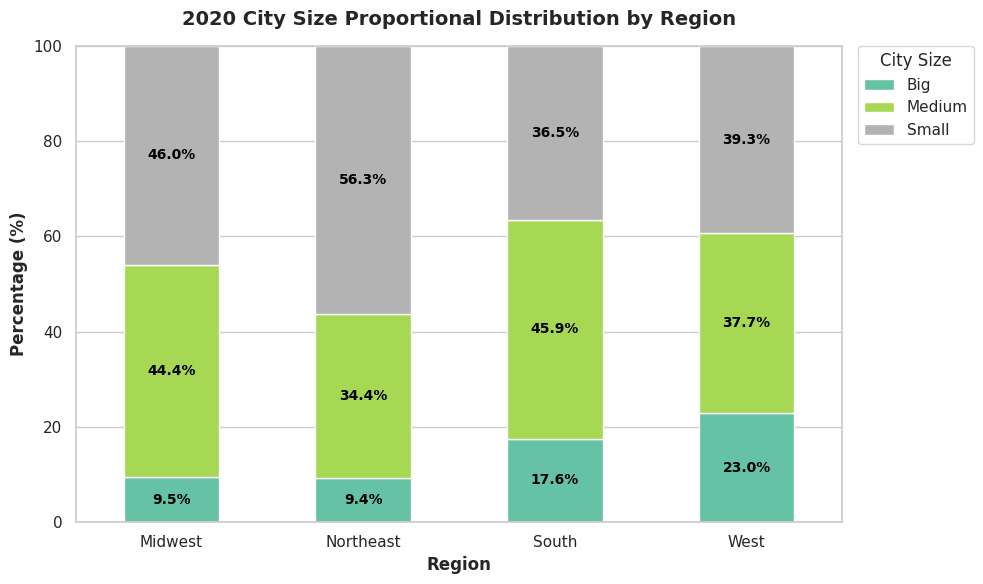

In [ ]:
def tier_list(df):
    df_clean = df.copy()

    # Define tier column
    tier_col = 'Size Tier'

    # Filter only for big, medium, and small cities
    target_tiers = ['Big', 'Medium', 'Small']
    df_filtered = df_clean[df_clean[tier_col].isin(target_tiers)].copy()

    # Ensure standard data type
    df_filtered['Population'] = pd.to_numeric(
        df_filtered['Population'].astype(str).str.replace(',', '', regex = False),
        errors = 'coerce',
    )

    # Identify baseline 2020 population by city and state
    df_2020 = df_filtered[df_filtered['Year'].astype(str) == '2020'].drop_duplicates(
        subset = ['City', 'State']
    )

    # Sort descending per tier
    df_sorted = df_2020.sort_values(
        by = [tier_col, 'Population'], ascending = [True, False]
    )

    result = df_sorted[
        ['City', 'State', 'Region', 'Population', tier_col]
    ].reset_index(drop = True)

    return result

cities_descending = tier_list(merged_data)
tier_col = cities_descending.columns[-1]
reg_col = cities_descending.columns[2]

# Pivot city count per region and size tier
pivot_df = cities_descending.pivot_table(
    index = reg_col,
    columns = tier_col,
    values = 'City',
    aggfunc = 'count',
    fill_value = 0
)

# Normalize city counts to stacked percentages (100%) of region
pivot_pct = pivot_df.div(pivot_df.sum(axis = 1), axis = 0) * 100

# Create the chart
ax = pivot_pct.plot(
    kind = 'bar', stacked = True, figsize = (10, 6), colormap = 'Set2'
)

# Add labels inside per segment
for container in ax.containers:
  labels = [
      f'{v.get_height():.1f}%' if v.get_height() > 5 else '' for v in container
  ]
  ax.bar_label(
      container,
      labels = labels,
      label_type = 'center',
      fontsize = 10,
      fontweight = 'bold',
      color = 'black',
  )

# Add formatting customizations to chart
plt.title(
    '2020 City Size Proportional Distribution by Region',
    fontsize = 14,
    fontweight = 'bold',
    pad = 15,
)

plt.xlabel('Region',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Percentage (%)',
           fontsize = 12,
           fontweight = 'bold')
plt.ylim(0, 100)
plt.xticks(rotation = 0)
plt.legend(
    loc = 'upper left',
    title = 'City Size',
    bbox_to_anchor = (1.02, 1),
    borderaxespad = 0,
)

plt.tight_layout()
plt.show()

# **Graph 2: Top 15 Populated City Walkability and Transit Use Correlation**

**Question 2:**
<br>
How closely does city-level Walkability align with Transit Usage (Unlinked Passenger Trips per Capita) across the top 15 populated cities?

**Analysis:**
<br>
The scatter plot demonstrates a strong positive correlation between city-level Walkability Index scores and transit usage per capita.
* High-Density Leaders: New York (Walkability ~14.2) and San Francisco (Walkability ~15.4) lead with over 300–380 transit trips per capita, driven by dense urban layouts and extensive transit networks.
* Moderate Performers: Philadelphia, Chicago, and Los Angeles occupy the middle tier (Walkability 14.0–15.0, 100–150 trips per capita).
* Low-Walkability / Low-Transit Cities: Sprawling cities with walkability scores below 13.0 (e.g., Phoenix, Austin, Dallas, Jacksonville) cluster near the bottom with under 50 transit trips per capita.

The regression line confirms that higher walkability suggeests greater transit reliance, though major transit infrastructure introduces wider variance at higher walkability levels.

**Answer:**
<br>
Yes, walkability aligns strongly and positively with transit usage per capita. High-walkability cities (index > 14) see significantly higher public transit reliance, whereas low-walkability cities (index < 13) record consistently low transit usage across the top 15 populated cities.


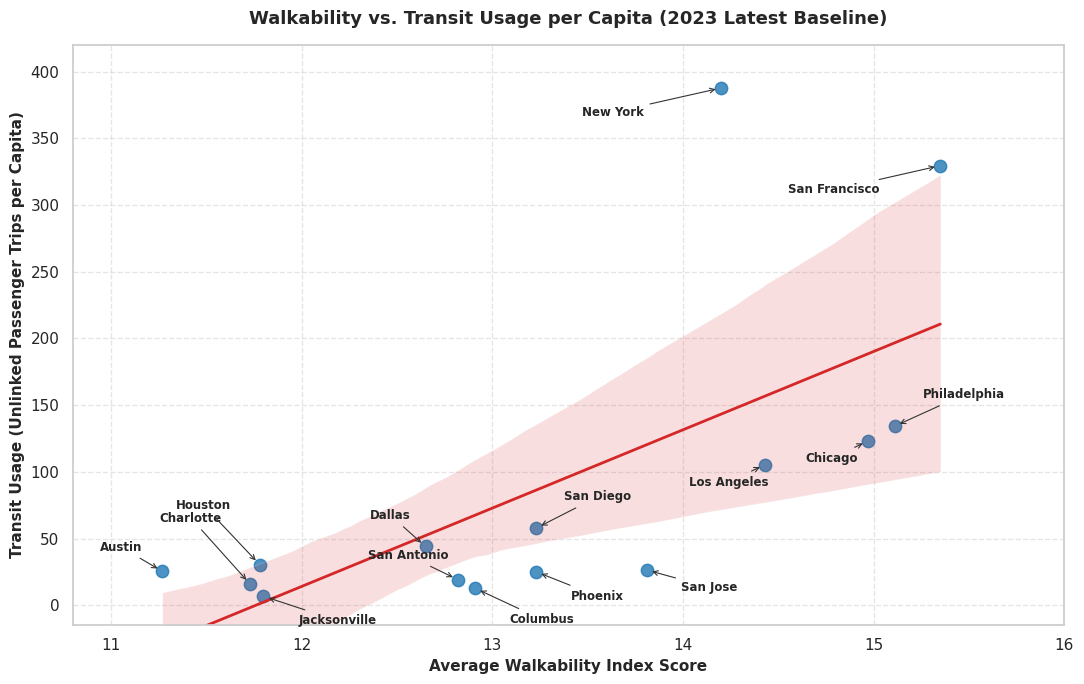

In [ ]:
# Identify the top 15 populous cities in 2023
top15_cities = (
    con_score[con_score['Year'] == 2023]
    .sort_values(by = 'Population', ascending = False)
    .head(15)[['City', 'State']]
)

# Filter and merge top 15 populous cities on convenience score data
chart_data = con_score.merge(
    top15_cities, on = ['City', 'State'], how = 'inner'
)
chart_data = chart_data[chart_data['Year'] == 2023].copy()
plt.figure(figsize = (11, 7))
sns.regplot(
    data = chart_data,
    x = 'avg_walkability',
    y = 'Ridership_per_Capita',
    scatter_kws = {'s': 80, 'color': '#1f77b4'},
    line_kws = {'color': '#d62728', 'linewidth': 2}
)

# Custom offsets to ensure visual clarity
label_offsets = {
    'Austin': (-45, 15),
    'Charlotte': (-65, 45),
    'Houston': (-60, 40),
    'Jacksonville': (25, -20),
    'Dallas': (-40, 20),
    'San Antonio': (-65, 15),
    'Columbus': (25, -25),
    'Phoenix': (25, -20),
    'San Diego': (20, 20),
    'San Jose': (25, -15),
    'Los Angeles': (-55, -15),
    'Chicago': (-45, -15),
    'Philadelphia': (20, 20),
    'San Francisco': (-110, -20),
    'New York': (-100, -20)
}

# Annotate each city with arrows
for _, row in chart_data.iterrows():
    city = row['City']
    x = row['avg_walkability']
    y = row['Ridership_per_Capita']

    offset = label_offsets.get(city, (20, 10))

    plt.annotate(
        city,
        xy = (x, y),
        xytext = offset,
        textcoords = 'offset points',
        fontsize = 8.5,
        fontweight = 'bold',
        arrowprops = dict(
            arrowstyle = '->',
            color = '#333333',
            lw = 0.8,
            shrinkA = 2,
            shrinkB = 4
        )
    )

# Expand axis limits to prevent clipping
plt.xlim(10.8, 16.0)
plt.ylim(-15, 420)

plt.title('Walkability vs. Transit Usage per Capita (2023 Latest Baseline)',
          fontsize = 13,
          pad = 15,
          fontweight="bold")
plt.xlabel('Average Walkability Index Score',
           fontsize = 11,
           fontweight = 'bold')
plt.ylabel('Transit Usage (Unlinked Passenger Trips per Capita)',
           fontsize = 11,
           fontweight = 'bold')
plt.grid(True, linestyle = '--', alpha = 0.5)

plt.tight_layout()
plt.show()

# **Graph 3: Post-Pandemic Ridership Recovery Rate by City Size Tier**

**Question 3:**
<br>
Which population tier has achieved the highest post-pandemic (2023) transit ridership recovery rate relative to 2020 levels?

**Analysis:**
<br>
The bar chart compares percentage changes in transit ridership from 2020 to 2023 across three population tiers. Big cities experienced the largest increase at approximately 58%, followed by small cities at 53% and medium-sized cities at 40%. All three tiers experienced positive ridership growth over this period, indicating a recovery from pandemic-era levels.

**Answer:**
<br>
Big cities achieved the highest transit ridership recovery rate, with an increase of approximately 58% from 2020 to 2023. Small cities followed closely at around ~53%, while medium-sized cities saw the smallest increase at approximately 40%. This suggests that big and small cities experienced stronger ridership rebounds than medium-sized cities, although all three tiers showed positive recovery.


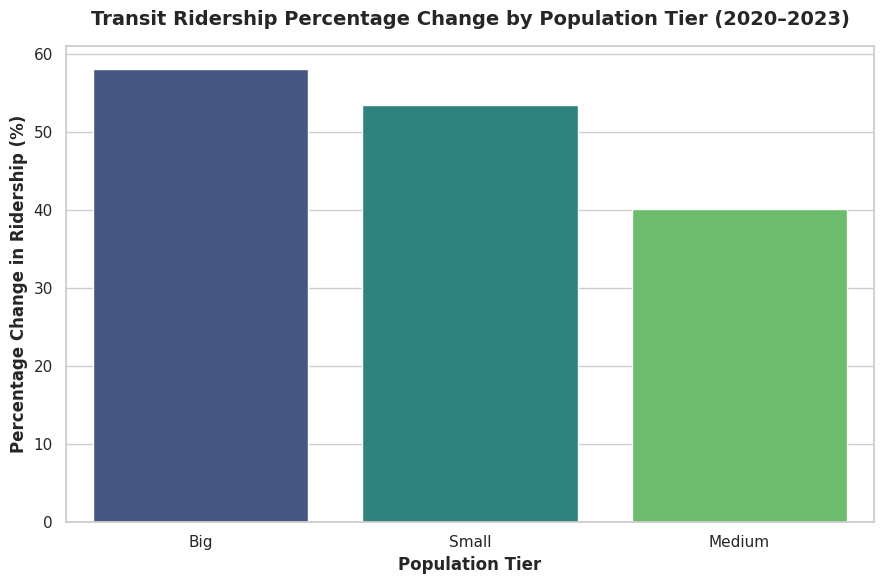

In [ ]:
# Keep only 2020 and 2023
recovery_data = merged_data[
    merged_data['Year'].isin([2020, 2023])
].copy()

# Sum ridership by population tier and year
ridership_by_tier = (
    recovery_data
    .groupby(['Size Tier', 'Year'], as_index = False)
    .agg(ridership = ('ridership', 'sum'))
)

# Put 2020 and 2023 ridership side by side
ridership_pivot = ridership_by_tier.pivot(
    index = 'Size Tier',
    columns = 'Year',
    values = 'ridership'
)

# Calculate percentage change from 2020 to 2023
ridership_pivot['Percentage Change (%)'] = (
    (ridership_pivot[2023] - ridership_pivot[2020])
    / ridership_pivot[2020] * 100
)

# Sort from highest to lowest percentage change
change_results = (
    ridership_pivot[['Percentage Change (%)']]
    .dropna()
    .reset_index()
    .sort_values('Percentage Change (%)', ascending = False)
)

# Plot percentage change
plt.figure(figsize = (9, 6))
ax = sns.barplot(
    data = change_results,
    x = 'Size Tier',
    y = 'Percentage Change (%)',
    hue = 'Size Tier',
    palette = 'viridis',
    legend = False
)

plt.title('Transit Ridership Percentage Change by Population Tier (2020–2023)',
          fontsize = 14,
          pad = 15,
          fontweight = 'bold')
plt.xlabel('Population Tier', fontsize = 12, fontweight = 'bold')
plt.ylabel('Percentage Change in Ridership (%)', fontsize = 12, fontweight = 'bold')
plt.tight_layout()
plt.show()

# **Graph 4: Transit Funding vs. City Population by Tier**

**Question 4:**
<br>
Is total transit funding proportional to city population size across city tiers?

**Analysis:**
<br>
Total transit funding exhibits a clear scale dependency across city tiers:
* Large Cities: Strong positive linear correlation where population size drives funding exponentially up to multi-billion-dollar allocations.
* Medium Cities: Moderate positive correlation with higher funding variance and several large-budget outliers (\$800M-\$1B).
* Small Cities: Flat correlation with low baseline funding (<$50M) regardless of population size.

**Answer:**
<br>
Yes, total transit funding is generally proportional to city population size, but the strength of this relationship varies significantly across city tiers. Large cities show a strong positive correlation, medium cities display a moderate trend, and small cities show virtually no proportionality, maintaining low baseline funding regardless of population size.


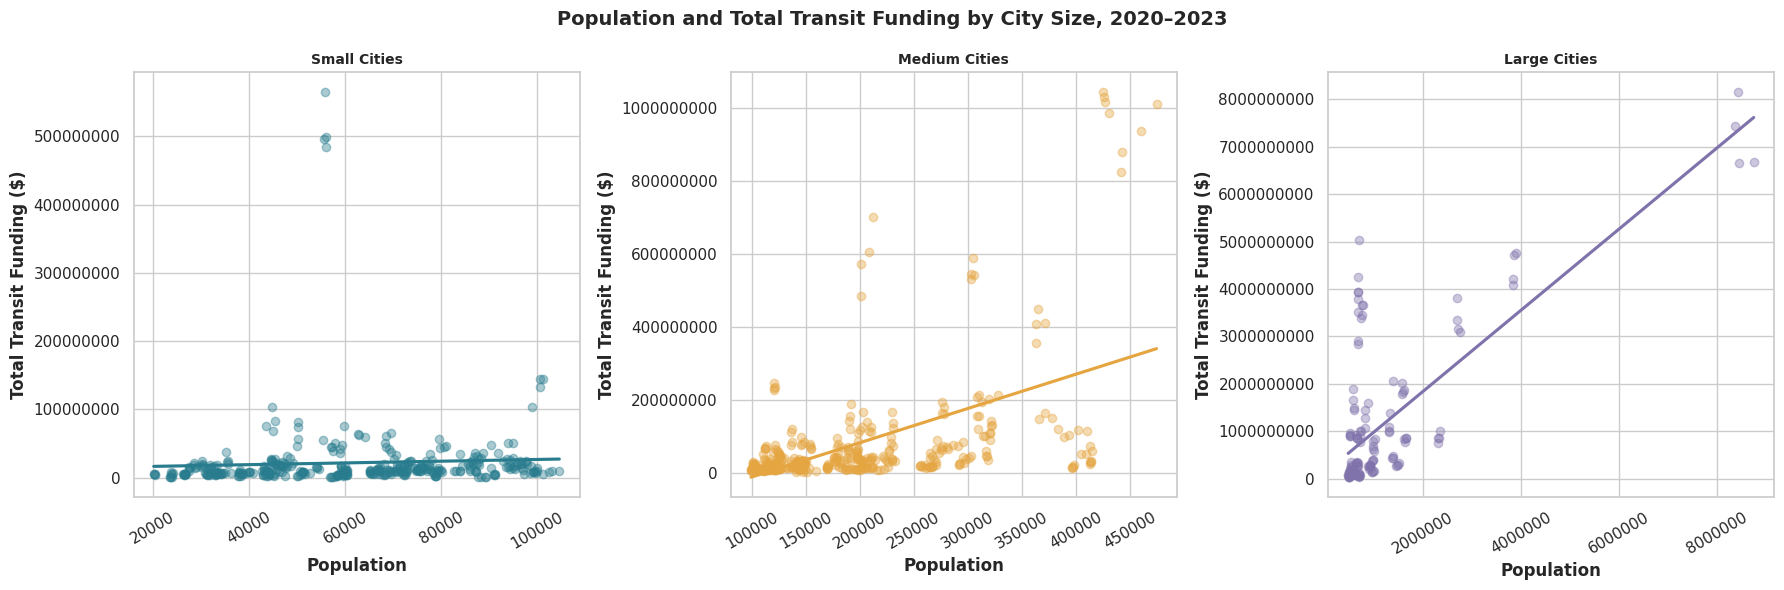

In [ ]:
# Select data from 2020 to 2023
data = merged_data[merged_data['Year'].between(2020, 2023)]

# Plot population and total funding by city size
fig, axes = plt.subplots(1, 3, figsize = (18, 6))

for ax, tier, label, color in zip(
    axes,
    ['Small', 'Medium', 'Big'],
    ['Small Cities', 'Medium Cities', 'Large Cities'],
    ['#287C8E', '#E5A540', '#8073AC']
):
    group = data[data['Size Tier'] == tier]

    sns.regplot(
        data = group,
        x = 'Population',
        y = 'Funding',
        color = color,
        scatter_kws = {'alpha': 0.4},
        ci = None,
        ax = ax
    )


    ax.set_title(label,
                 fontsize = 10,
                 fontweight = 'bold')
    ax.set_xlabel('Population',
                  fontsize = 12,
                  fontweight = 'bold')
    ax.set_ylabel('Total Transit Funding ($)',
                  fontsize = 12,
                  fontweight = 'bold')
    ax.ticklabel_format(style = 'plain', axis = 'both')
    ax.tick_params(axis = 'x', rotation = 30)

plt.suptitle('Population and Total Transit Funding by City Size, 2020–2023',
             fontsize = 14,
             fontweight = 'bold')
plt.tight_layout()
plt.show()

# **Graph 5: Population Growth and Walkability Correlation**

**Question 5:**
<br>
Is 2020–2023 population growth associated with a change in city-level Walkability scores across small, medium, and big cities?

**Analysis:**
<br>
The scatter plot with trend lines shows the scatter plots and regression line charts of the Small, Medium, and Big city size tiers on a plot showing population growth as a percentage and walkability change as a score from 2020 to 2023. Medium cities trended upwards to show a slight increase in both walkability and major population growth. Big cities trended slightly downward in walkability but kept steady increase of 5% in population growth. Small cities had the most noticeable change of increased walkability and population growth over the 2020 to 2023 time period.

**Answer:**
<br>
There is a minimal association between population growth and walkability scores across the big and medium city size tiers, provided the scatter plot shows near 0 correlation, and correlation regression does not provide clear evidence to support that an established correlation exists. A correlation can be investigated and derived from small city population growth compared with walkability changes.

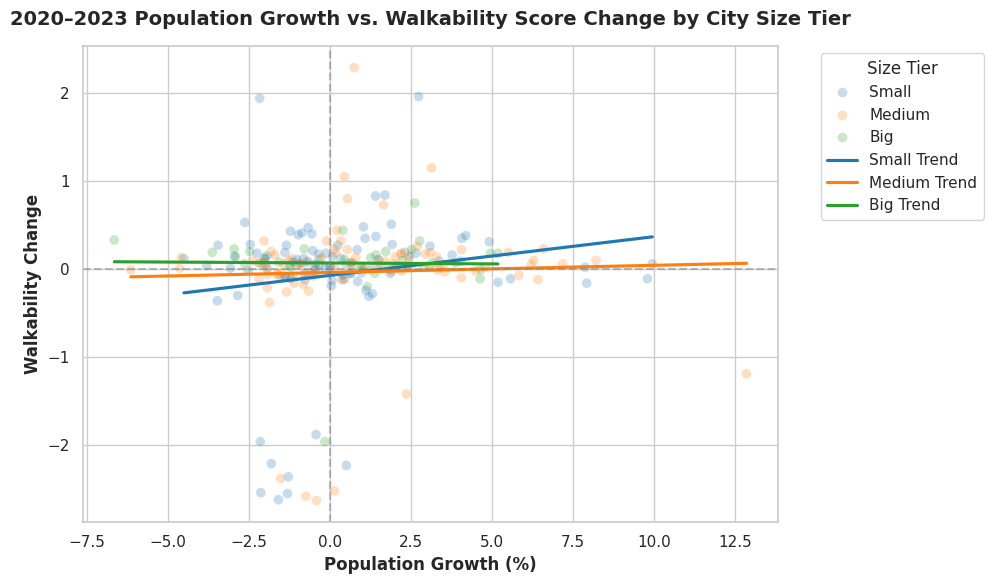

In [ ]:
# Create copy data to avoid editing true data
merged_data_copy = merged_data.copy()

# Calculate and index base 2020 and 2023 population data
pop_2020 = merged_data_copy[merged_data_copy['Year'] == 2020].set_index(['City', 'State'])['Population']
pop_2023 = merged_data_copy[merged_data_copy['Year'] == 2023].set_index(['City', 'State'])['Population']

# Calculate 2020-2023 Population Growth Percentage
pop_growth = ((pop_2023 - pop_2020) / pop_2020) * 100

# Calculate average walkability per city
walk_2020 = merged_data_copy[merged_data_copy['Year'] == 2020].set_index(['City', 'State'])['avg_walkability']
walk_2023 = merged_data_copy[merged_data_copy['Year'] == 2023].set_index(['City', 'State'])['avg_walkability']
walk_change = walk_2023 - walk_2020

# Identify size tier per city
tiers = merged_data_copy[['City', 'State', 'Size Tier']].drop_duplicates().set_index(['City', 'State'])['Size Tier']

# Combine into a summary DataFrame
q5_df = pd.DataFrame({
    'Size Tier': tiers,
    'Pop Growth (%)': pop_growth,
    'Walkability Change': walk_change
}).dropna().reset_index()

tier_order = ['Small', 'Medium', 'Big']
tier_colors = {'Small': '#1f77b4', 'Medium': '#ff7f0e', 'Big': '#2ca02c'}

plt.figure(figsize=(10, 6))

# Create a scatter plot for all tiers
sns.scatterplot(
    data = q5_df,
    x = 'Pop Growth (%)',
    y = 'Walkability Change',
    hue = 'Size Tier',
    hue_order = tier_order,
    palette = tier_colors,
    alpha = 0.25,
    s = 50,
)

# Overlay regression trend lines for each tier
for tier in tier_order:
    subset = q5_df[q5_df['Size Tier'] == tier]
    sns.regplot(
        data = subset,
        x = 'Pop Growth (%)',
        y = 'Walkability Change',
        scatter = False,
        color = tier_colors[tier],
        label = f'{tier} Trend',
        ci = None
    )

# Baseline x, y axes
plt.axhline(0, color = 'gray', linestyle = '--', alpha = 0.5)
plt.axvline(0, color = 'gray', linestyle = '--', alpha = 0.5)

plt.title(
    '2020–2023 Population Growth vs. Walkability Score Change by City Size Tier',
    fontsize = 14,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Population Growth (%)',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Walkability Change',
           fontsize = 12,
           fontweight = 'bold')
plt.legend(title = 'Size Tier', bbox_to_anchor = (1.05, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

# **Graph 6: City Size Tier Return on Transit Funding**

**Question 6:**
<br>
Which population tier delivers the highest transit ridership per dollar of public funding allocated?

**Analysis:**
<br>
* Small cities have the highest transit ridership per dollar of funding, at approximately **0.083**, followed by medium cities at **0.079** and large cities at **0.077**.
* The differences between the three tiers are relatively small, suggesting that ridership per dollar of funding is similar across population tiers.
* These results suggest that smaller cities generate slightly more transit ridership per dollar allocated, although this metric alone does not account for service quality, operating costs, or differences in funding needs.

**Answer:**
<br>
Small cities deliver the highest transit ridership per dollar of public funding, followed by medium and large cities. However, the differences are modest, so smaller cities appear slightly more efficient by this measure rather than definitively more efficient overall.

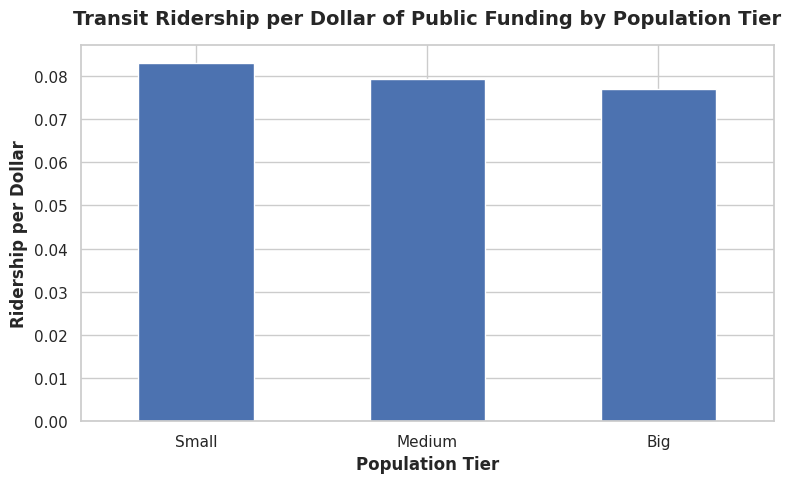

Highest tier: Small


In [ ]:
# Calculate ridership per dollar of funding
con_score['Ridership_per_Dollar'] = (
    con_score['ridership'] / con_score['Funding']
)

# Compare average by population tier
tier_ridership = con_score.groupby('Size Tier')['Ridership_per_Dollar'].mean().sort_values(ascending = False)

# Plot
tier_ridership.plot(kind = 'bar', figsize = (8, 5))

plt.title('Transit Ridership per Dollar of Public Funding by Population Tier',
          fontsize = 14,
          fontweight = 'bold',
          pad = 15)
plt.xlabel('Population Tier',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Ridership per Dollar',
           fontsize = 12,
           fontweight = 'bold')
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

print('Highest tier:', tier_ridership.idxmax())

# **Graph 7: Head & Tail Sub-Metric Relative Contribution**

**Question 7:**
<br>
What is the relative contribution of each sub-metric (Transit Usage, Funding per Capita, and Walkability) to the overall score for the top 5 and bottom 5 ranked cities?

**Analysis:**
<br>
Boston and Washington show relatively balanced contributions across funding, transit usage, and walkability. Walkability contributes about half of Seattle’s score and over half of San Francisco’s, while funding accounts for approximately 53% of Olympia’s. Among the bottom five, walkability contributes approximately 95% in Sherman, 88% in Evansville, and 78% in Elizabethtown. Gulfport has a more balanced composition, while walkability remains Rome’s largest component.

**Answer:**
<br>
The top five cities have different strengths: Boston and Washington combine all three components, Seattle and San Francisco rely more on walkability, and Olympia relies primarily on funding. Several bottom-five cities depend heavily on walkability because their normalized funding and transit usage contributions are small.

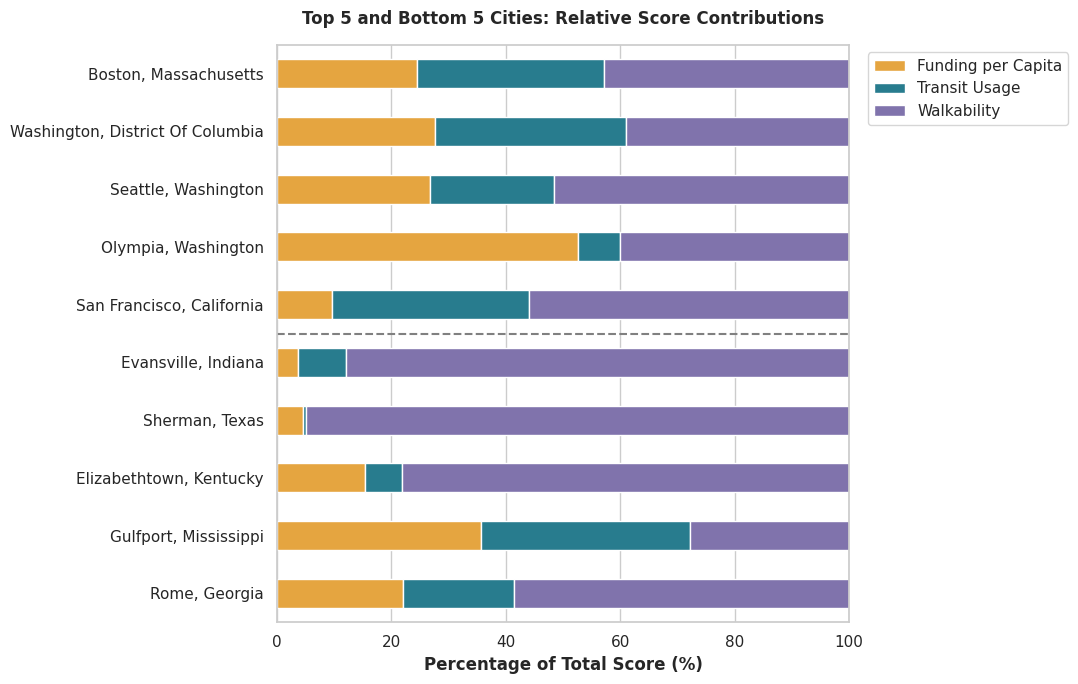

In [ ]:
# Rank cities by their average existing scores
scores = con_score.groupby(['City', 'State'])[
    [
        'FundingScore', 'RidershipScore',
        'WalkabilityScore', 'Convenience_Score_100'
    ]
].mean().sort_values('Convenience_Score_100', ascending = False)

# Select the top five and bottom five cities
selected = pd.concat([scores.head(5), scores.tail(5)])
selected.index = [
    f'{city}, {state}' for city, state in selected.index
]

# Calculate each component's percentage of the total score
contributions = selected[
    ['FundingScore', 'RidershipScore', 'WalkabilityScore']
]
contributions = contributions.div(
    contributions.sum(axis = 1).replace(0, float('nan')), axis = 0
) * 100

contributions.columns = [
    'Funding per Capita', 'Transit Usage', 'Walkability'
]

# Plot percentage contributions
ax = contributions.plot.barh(
    stacked = True,
    figsize = (11, 7),
    color = ['#E5A540', '#287C8E', '#8073AC']
)

ax.invert_yaxis()
ax.axhline(4.5, color = 'gray', linestyle = '--')
ax.set_xlim(0, 100)
ax.set_xlabel('Percentage of Total Score (%)',
              fontsize = 12,
              fontweight = 'bold')
ax.set_ylabel('')
ax.set_title('Top 5 and Bottom 5 Cities: Relative Score Contributions',
             fontsize = 12,
             fontweight = 'bold',
             pad = 15)
ax.legend(title='', bbox_to_anchor = (1.02, 1), loc = 'upper left')
plt.tight_layout()
plt.show()

# **Graph 8: City Size Tier Transportation Convenience Score Performance and Variance**

**Question 8:**
<br>
Which population tier (Small, Medium, or Large) performs best overall in median Transportation Convenience Score, and which tier shows the highest score variance?

**Analysis:**
<br>
* Large cities have the highest median Transportation Convenience Score at approximately **26**, compared with about **23** for medium and small cities.
* The error bars represent standard deviation, not variance directly. Large cities show the greatest variability in convenience scores, while medium and small cities have similar levels of variation.
* The differences in median scores are relatively small compared with the variation within each tier, suggesting that population size alone may not fully explain transportation convenience.

**Answer:**
<br>
Large cities perform best in median Transportation Convenience Score and show the greatest variability in scores. However, the overlapping error bars suggest substantial variation within all three population tiers.


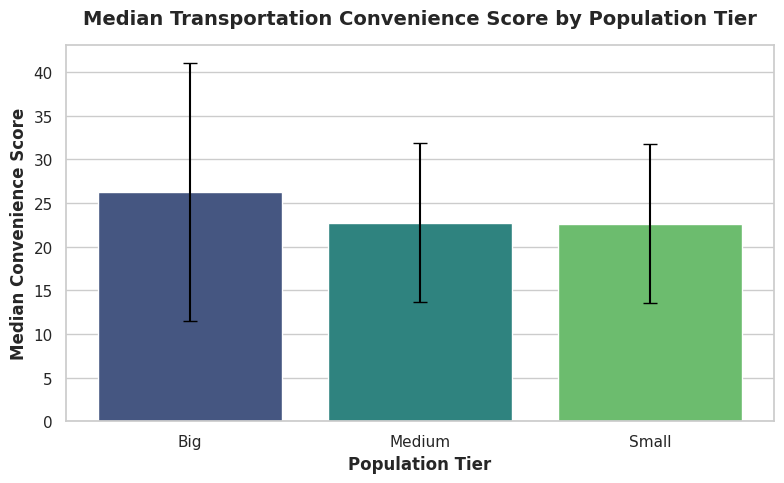

In [ ]:
# Calculate median convenience score and standard deviation by population tier
tier_analysis = (
    con_score.groupby('Size Tier')['Convenience_Score_100']
    .agg(Median_Score = 'median', Score_Std = 'std')
    .reset_index()
)

# Create bar chart
plt.figure(figsize = (8, 5))

sns.barplot(
    data = tier_analysis,
    x = 'Size Tier',
    y = 'Median_Score',
    hue = 'Size Tier',
    legend = False,
    palette = 'viridis'
)

# Add standard deviation error bars
plt.errorbar(
    x = range(len(tier_analysis)),
    y = tier_analysis['Median_Score'],
    yerr = tier_analysis['Score_Std'],
    fmt = 'none',
    color = 'black',
    capsize = 5
)

# Format graph
plt.title('Median Transportation Convenience Score by Population Tier',
          fontsize = 14,
          fontweight = 'bold',
          pad = 15)
plt.xlabel('Population Tier',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Median Convenience Score',
           fontsize = 12,
           fontweight = 'bold')
plt.tight_layout()
plt.show()

# **Graph 9: Transportation Convenience Score Performance Annual Delta Over City Size Tiers**

**Question 9:**
<br>
How did the average Transportation Convenience Score evolve annually from 2020 to 2023 across small, medium, and large cities?

**Analysis:**
<br>
Large cities consistently recorded the highest average Convenience Scores, rising from approximately 31 in 2020 to 34 in 2023, with most growth occurring after 2021. Medium and small cities remained relatively stable at around 23 and 22, respectively, with slight increases. The scatter points show substantial variation within each tier, with some smaller cities exceeding the large-city average.

**Answer:**
<br>
Average transportation convenience improved slightly across all three tiers between 2020 and 2023. Large cities showed the clearest improvement and maintained their lead, while small and medium cities experienced limited changes.

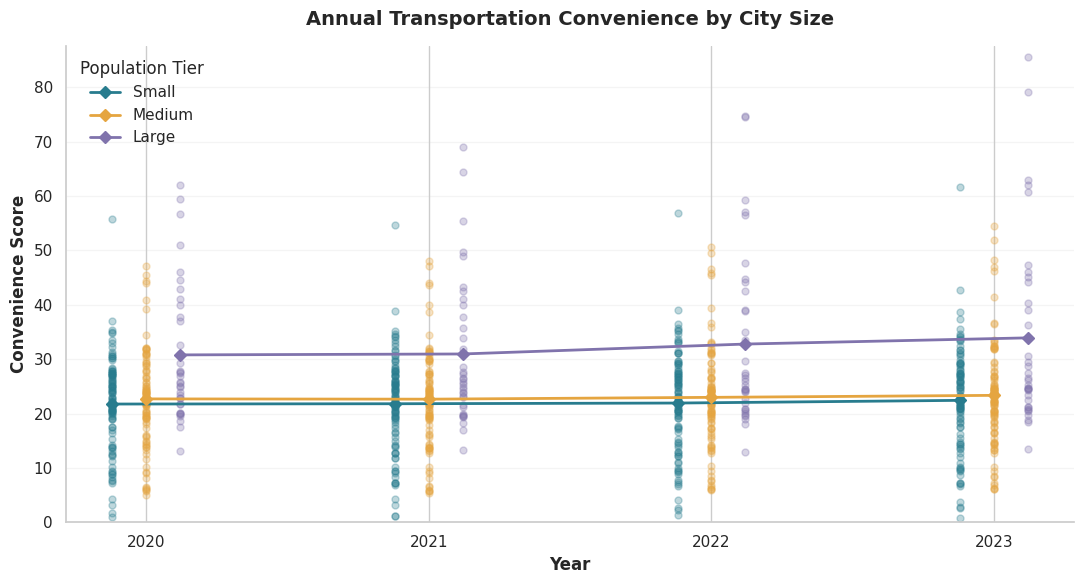

In [ ]:
# Select the study years and population tiers
data = con_score[
    con_score['Year'].between(2020, 2023)
    & con_score['Size Tier'].isin(['Small', 'Medium', 'Big'])
]

fig, ax = plt.subplots(figsize = (11, 6))

for tier, label, color, offset in [
    ('Small', 'Small', '#287C8E', -0.12),
    ('Medium', 'Medium', '#E5A540', 0),
    ('Big', 'Large', '#8073AC', 0.12)
]:
    group = data[data['Size Tier'] == tier]

    # Plot individual city scores
    ax.scatter(
        group['Year'] + offset, group['Convenience_Score_100'],
        color = color, alpha = 0.3, s = 25
    )

    # Plot annual average scores
    average = group.groupby('Year')['Convenience_Score_100'].mean()
    ax.plot(
        average.index + offset, average,
        color = color, marker = 'D', linewidth = 2, label = label
    )

# Adjust the axis range to the displayed scores
ax.set_ylim(
    max(0, data['Convenience_Score_100'].min() - 2),
    min(100, data['Convenience_Score_100'].max() + 2)
)
ax.set_xticks([2020, 2021, 2022, 2023])
ax.set_xlabel('Year',
              fontsize = 12,
              fontweight = 'bold')
ax.set_ylabel('Convenience Score',
              fontsize = 12,
              fontweight = 'bold')
ax.set_title('Annual Transportation Convenience by City Size',
             fontsize = 14,
             fontweight = 'bold',
             pad = 15)
ax.legend(title = 'Population Tier', frameon = False)
ax.grid(axis = 'y', alpha = 0.2)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

# **Graph 10: Population Growth Correlation with City Transportation Convenience Score Variance**

**Question 10:**
<br>
Is 2020–2023 population growth associated with an increase or decrease in a city’s Transportation Convenience Score?

**Analysis:**
<br>
The four-quadrant scatter plot compares population growth with percentage changes in Transportation Convenience Scores across 230 cities from 2020 to 2023. The correlation coefficient is approximately 0.03, indicating virtually no linear relationship between population growth and convenience score changes. Most cities cluster near zero on both axes, although a few cities experienced substantial increases or decreases in convenience. Cities in the lower-right quadrant experienced population growth alongside declining convenience, while those in the upper-right quadrant experienced increases in both.

**Answer:**
<br>
Population growth was not meaningfully associated with changes in Transportation Convenience Scores between 2020 and 2023. Although some growing cities experienced declining convenience, the near-zero correlation (r = 0.03) suggests that population growth alone does not explain changes in transportation convenience. Further analysis of individual cities, population tiers, and transportation investment may help identify factors associated with declining convenience.


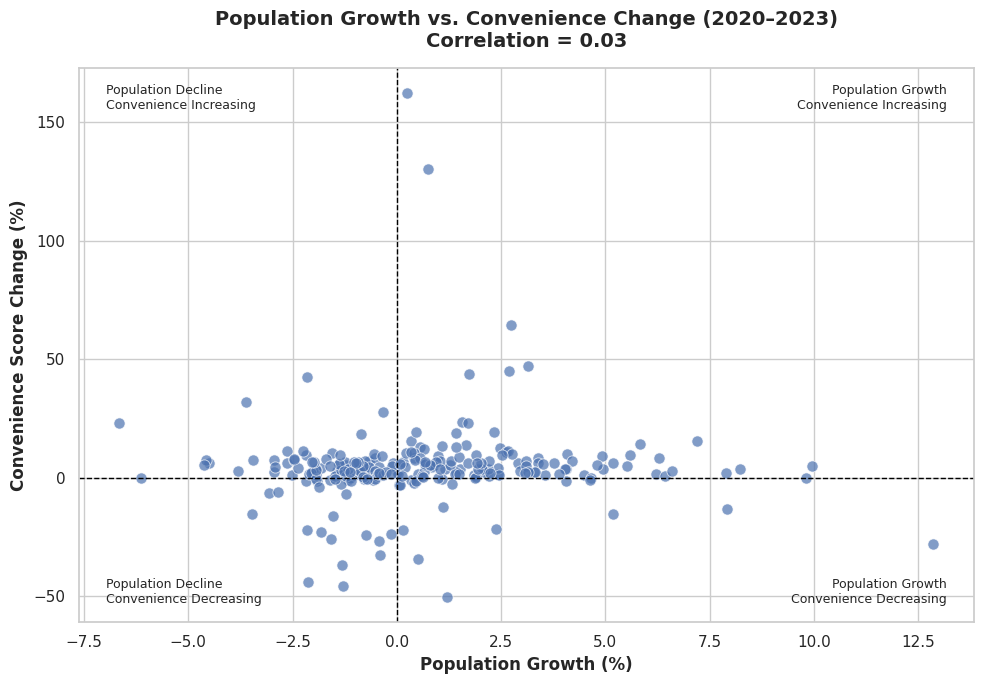

Number of cities analyzed: 230
Correlation: 0.030


In [ ]:
# Keep cities with data in both 2020 and 2023
df = con_score[con_score['Year'].isin([2020, 2023])].copy()

df = df[
    df.groupby(['City', 'State'])['Year'].transform('nunique') == 2
]

# Get 2020 and 2023 population and convenience scores
population = df.pivot_table(
    index = ['City', 'State'],
    columns = 'Year',
    values = 'Population',
    aggfunc = 'first'
)

convenience = df.pivot_table(
    index = ['City', 'State'],
    columns = 'Year',
    values = 'Convenience',
    aggfunc = 'first'
)

# Calculate percentage changes
changes = pd.DataFrame(index = population.index)

changes['Population Growth (%)'] = (
    (population[2023] - population[2020])
    / population[2020] * 100
)

# Percentage change in convenience score
changes['Convenience Change (%)'] = (
    (convenience[2023] - convenience[2020])
    / convenience[2020].replace(0, np.nan) * 100
)

changes = changes.replace([np.inf, -np.inf], np.nan).dropna()

# Calculate correlation
correlation = changes['Population Growth (%)'].corr(
    changes['Convenience Change (%)']
)

# Plot four-quadrant scatter plot
plt.figure(figsize = (10, 7))

sns.scatterplot(
    data = changes,
    x = 'Population Growth (%)',
    y = 'Convenience Change (%)',
    alpha = 0.7,
    s = 65
)

# Quadrant dividing lines
plt.axhline(0, color = 'black', linewidth = 1, linestyle = '--')
plt.axvline(0, color = 'black', linewidth = 1, linestyle = '--')

# Label the quadrants
ax = plt.gca()
ax.text(
    0.97, 0.97, 'Population Growth\nConvenience Increasing',
    transform = ax.transAxes, ha = 'right', va = 'top', fontsize = 9
)
ax.text(
    0.03, 0.97, 'Population Decline\nConvenience Increasing',
    transform = ax.transAxes, ha = 'left', va = 'top', fontsize = 9
)
ax.text(
    0.97, 0.03, 'Population Growth\nConvenience Decreasing',
    transform = ax.transAxes, ha = 'right', va = 'bottom', fontsize = 9
)
ax.text(
    0.03, 0.03, 'Population Decline\nConvenience Decreasing',
    transform = ax.transAxes, ha = 'left', va = 'bottom', fontsize = 9
)

plt.title(
    f'Population Growth vs. Convenience Change (2020–2023)\n'
    f'Correlation = {correlation:.2f}',
    fontsize = 14,
    fontweight = 'bold',
    pad = 15
)
plt.xlabel('Population Growth (%)',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Convenience Score Change (%)',
           fontsize = 12,
           fontweight = 'bold')
plt.tight_layout()
plt.show()

print(f"Number of cities analyzed: {len(changes)}")
print(f"Correlation: {correlation:.3f}")

# **Graph 11: Large City Transportation Convenience Performance in Small & Medium City Tiers**

**Question 11:**
<br>
Which medium and small cities offer “large-city convenience scores” at lower population scales?

**Analysis:**
<br>
Using the large-city average of approximately 32.1 as the benchmark, 11 small and 11 medium cities meet or exceed this level. Olympia leads the small-city group at 57.3, followed by Harrisburg at 39.4. Among medium cities, Miami scores highest at 50.1, followed by Salt Lake City (48.5), Pittsburgh (45.7), and Minneapolis (45.1).

**Answer:**
<br>
Olympia and Harrisburg, along with Miami, Salt Lake City, Pittsburgh, and Minneapolis, offer above-average large-city convenience scores at lower population scales. These findings show that higher transportation convenience is not exclusive to large cities.

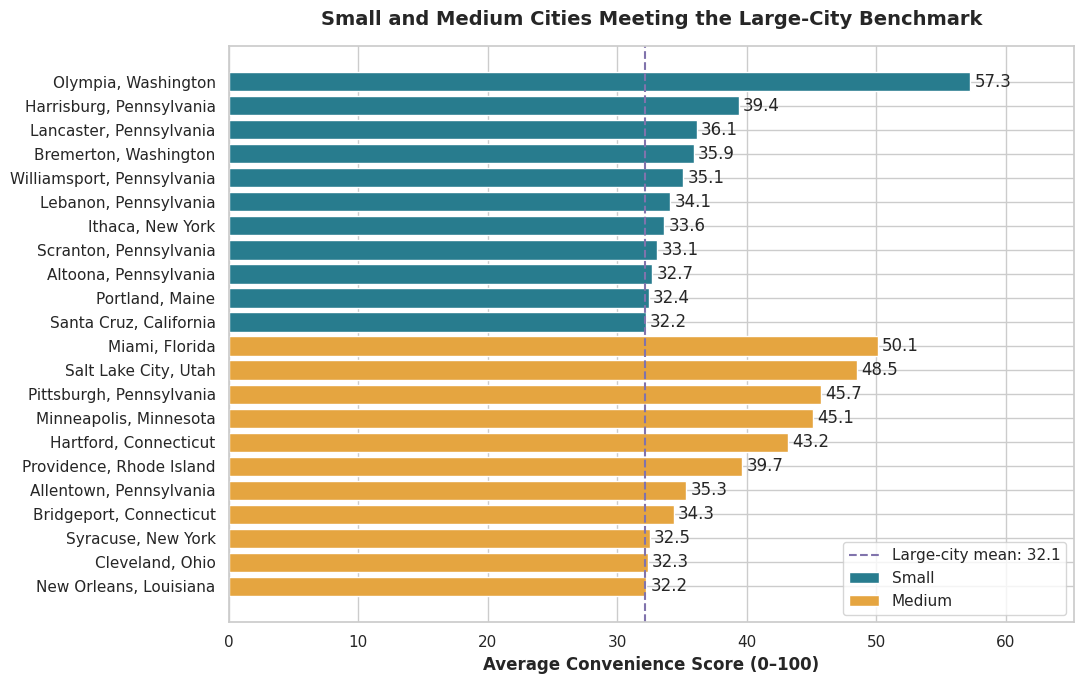

In [ ]:
# Calculate average city scores
city_scores = con_score.groupby(
    ['City', 'State', 'Size Tier'], as_index = False
)['Convenience_Score_100'].mean()

# Use the large-city mean as the benchmark
benchmark = city_scores.loc[
    city_scores['Size Tier'] == 'Big', 'Convenience_Score_100'
].mean()

# Select qualifying small and medium cities
qualified = city_scores[
    city_scores['Size Tier'].isin(['Small', 'Medium'])
    & (city_scores['Convenience_Score_100'] >= benchmark)
].sort_values('Convenience_Score_100', ascending = False)

# Plot both population tiers
fig, ax = plt.subplots(figsize = (11, 7))

for tier, label, color in [
    ('Small', 'Small', '#287C8E'),
    ('Medium', 'Medium', '#E5A540')
]:
    group = qualified[qualified['Size Tier'] == tier]
    bars = ax.barh(
        group['City'] + ', ' + group['State'],
        group['Convenience_Score_100'],
        color = color, label = label
    )
    ax.bar_label(bars, fmt = '%.1f', padding = 3)

# Mark the large-city benchmark
ax.axvline(
    benchmark, color = '#8073AC', linestyle = '--',
    label = f'Large-city mean: {benchmark:.1f}'
)

ax.invert_yaxis()
ax.set_xlim(0, qualified['Convenience_Score_100'].max() + 8)
ax.set_xlabel('Average Convenience Score (0–100)',
              fontsize = 12,
              fontweight = 'bold')
ax.set_title('Small and Medium Cities Meeting the Large-City Benchmark',
             fontsize = 14,
             fontweight = 'bold',
             pad = 15)
ax.legend()
plt.tight_layout()
plt.show()

# **Graph 12: Transportation Convenience Score Performance Across City Size Tier & Region**

**Question 12:**
<br>
How do Convenience Scores vary when cross-analyzed by U.S. Region (Northeast, Midwest, South, West) and Population Tier?

**Analysis:**
<br>
The grouped bar chart compares average Convenience Scores across four regions and three population tiers. The Northeast shows the largest gap between large cities (55.7) and medium cities (33.0). Small and medium Southern cities score 15.3 and 18.9, respectively. In the Midwest, scores increase from 21.4 for small cities to 27.0 for large cities. In the West, small cities (25.4) score above medium cities (24.6), while large cities lead at 32.9.

**Answer:**
<br>
The Northeast has the highest average Convenience Scores across all population tiers. Large cities score highest within every region, while small Southern cities have the lowest average. In the West, small cities average 25.4, exceeding medium cities at 24.6.


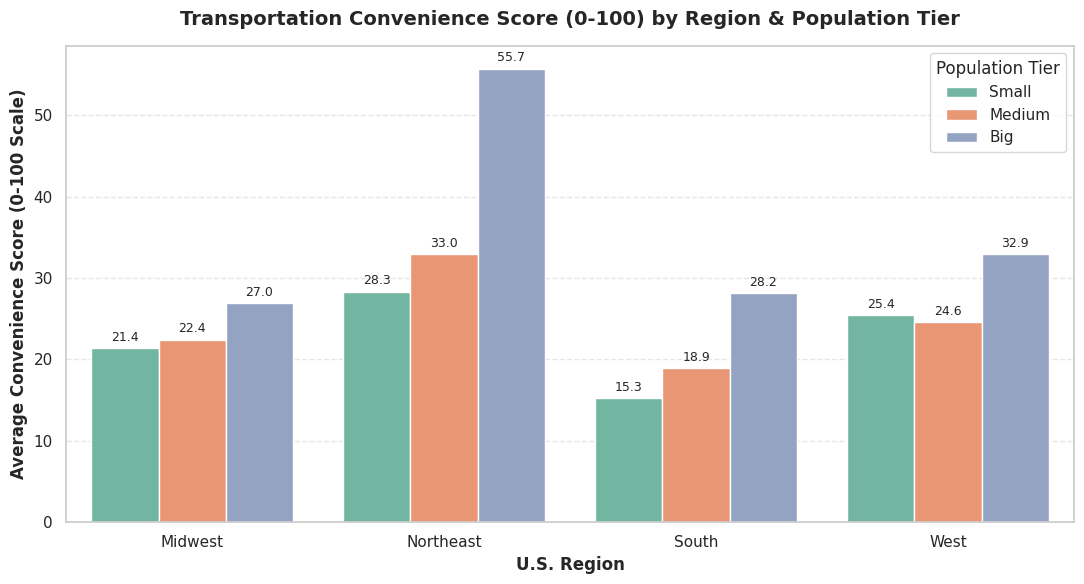

In [ ]:
# Create a working copy and convert score to 0-100 scale
df_region = con_score.copy()
df_region['Convenience_Score_100'] = (df_region['Convenience'] / 3) * 100

# Compute average score grouped by Region and Population Tier
region_tier_data = df_region.groupby(['Region', 'Size Tier'])['Convenience_Score_100'].mean().reset_index()

# Specify logical order for population tiers
tier_order = ['Small', 'Medium', 'Big']

# Render grouped bar chart
plt.figure(figsize = (11, 6))
sns.barplot(
    data = region_tier_data,
    x = 'Region',
    y = 'Convenience_Score_100',
    hue = 'Size Tier',
    hue_order = tier_order,
    palette = 'Set2'
)

# Display data label above each bar
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(
            f'{height:.1f}',
            (p.get_x() + p.get_width() / 2., height),
            ha = 'center', va = 'bottom', fontsize = 9, xytext = (0, 3), textcoords = 'offset points'
        )

# Format chart title, axes, legend, and layout
plt.title('Transportation Convenience Score (0-100) by Region & Population Tier',
          fontsize = 14,
          fontweight = 'bold',
          pad = 15)
plt.xlabel('U.S. Region',
           fontsize = 12,
           fontweight = 'bold')
plt.ylabel('Average Convenience Score (0-100 Scale)',
           fontsize = 12,
           fontweight = 'bold')
plt.legend(title = 'Population Tier', frameon = True)
plt.grid(axis = 'y', linestyle = '--', alpha = 0.5)

plt.tight_layout()
plt.show()

# **Graph 13: Transportation Convenience Score Factor Correlation**

**Question 13:**
<br>
Which underlying transportation variables (Walkability, Ridership per Capita, Funding per Capita) are most strongly correlated with high overall convenience?

**Analysis:**
<br>
The correlation heatmap shows that Walkability has the strongest positive correlation with the overall Transportation Convenience Score (0.85), followed by Ridership per Capita (0.77) and Funding per Capita (0.70). Funding per Capita and Ridership per Capita are also moderately to strongly correlated with each other (0.67), while Walkability has weaker correlations with Funding per Capita (0.30) and Ridership per Capita (0.38). These results suggest that walkability has the strongest association with overall convenience among the three measured components.

**Answer:**
<br>
Walkability is most strongly correlated with overall transportation convenience (r = 0.85), followed by Ridership per Capita (r = 0.77) and Funding per Capita (r = 0.70). This suggests that walkability may be an especially important indicator of transportation convenience across cities. However, because all three variables are used to calculate the overall convenience score, these correlations are partly built into the scoring formula and should not be interpreted as independent evidence of causation.


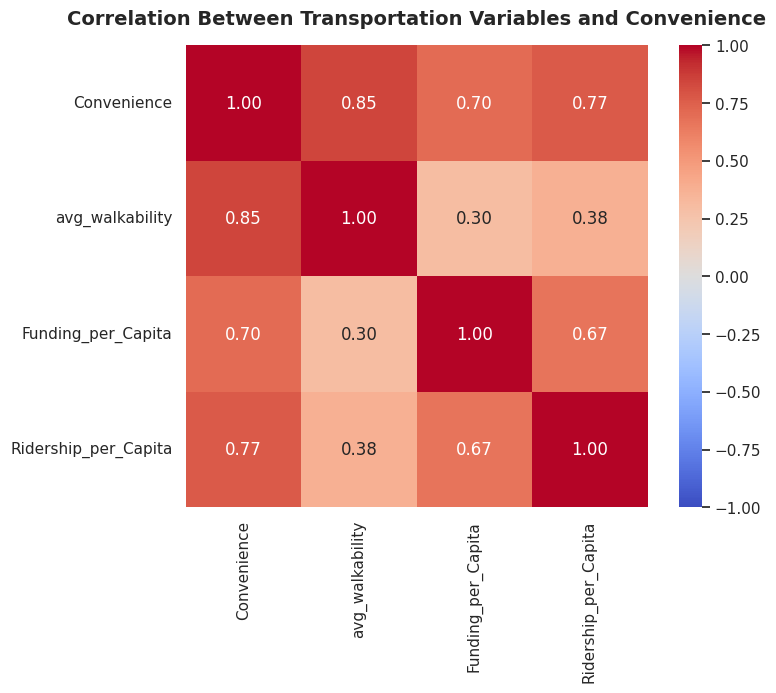

In [ ]:
# Select numeric transportation variables and the overall convenience score
correlation_columns = [
    'Convenience',
    'avg_walkability',
    'Funding_per_Capita',
    'Ridership_per_Capita'
    # Add ACS commute time and BLS metrics here if available
]

# Calculate correlations
correlation_matrix = con_score[correlation_columns].corr()

# Plot correlation heatmap
plt.figure(figsize = (8, 6))
sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap = 'coolwarm',
    vmin = -1,
    vmax = 1,
    center = 0,
    fmt = '.2f',
    square = True
)

plt.title('Correlation Between Transportation Variables and Convenience',
          fontsize = 14,
          fontweight = 'bold',
          pad = 15)
plt.show()

# **Graph 14: Transportation Convenience Score Factor and City Size Tier Sensitivity Analysis**

**Question 14:**
<br>
Which individual component of the convenience score (Walkability, Funding, or Ridership) is most sensitive to population growth shocks?

**Analysis:**
<br>
* Walkability has the strongest positive correlation with population growth at **0.09**, followed by Funding at **0.02** and Ridership at **-0.08**.
* All three correlations are close to zero, indicating that population growth has little relationship with changes in any individual component.
* Although Walkability is the most positively associated with population growth and Ridership shows a slight negative relationship, the differences are small and do not indicate meaningful sensitivity to population growth.

**Answer:**
<br>
Walkability is the most positively associated with population growth, while Ridership has a slight negative relationship. However, all three components show negligible correlations, suggesting that population growth alone does not meaningfully explain changes in transportation convenience.


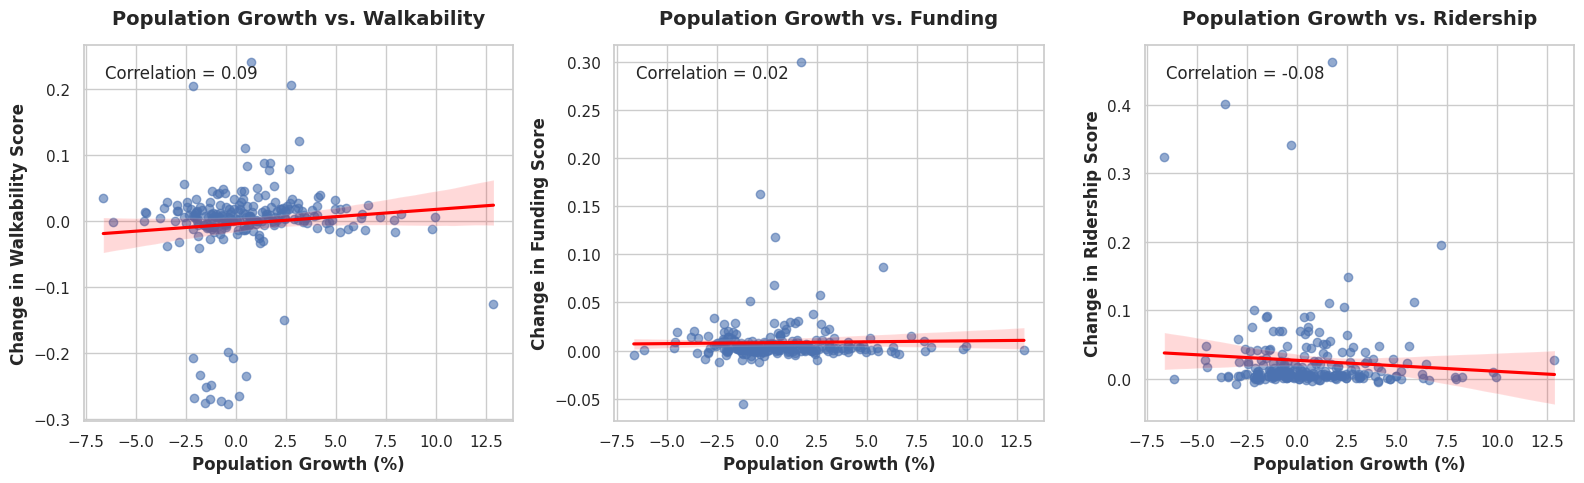

In [ ]:
# Keep cities with data in both 2020 and 2023
df = con_score[con_score['Year'].isin([2020, 2023])].copy()

df = df[
    df.groupby(['City', 'State'])['Year']
    .transform('nunique') == 2
]

# Pivot population and component scores
population = df.pivot(
    index = ['City', 'State'], columns = 'Year', values = 'Population'
)
walkability = df.pivot(
    index = ['City', 'State'], columns = 'Year', values = 'WalkabilityScore'
)
funding = df.pivot(
    index = ['City', 'State'], columns = 'Year', values = 'FundingScore'
)
ridership = df.pivot(
    index = ['City', 'State'], columns = 'Year', values = 'RidershipScore'
)

# Calculate population growth and score changes
changes = pd.DataFrame(index = population.index)

changes["Population Growth (%)"] = (
    (population[2023] - population[2020]) / population[2020] * 100
)
changes['Walkability Change'] = walkability[2023] - walkability[2020]
changes['Funding Change'] = funding[2023] - funding[2020]
changes['Ridership Change'] = ridership[2023] - ridership[2020]

changes = changes.replace([float('inf'), -float('inf')], float('nan')).dropna()

# Plot three panels
fig, axes = plt.subplots(1, 3, figsize = (16, 5))

components = [
    ('Walkability Change', 'Walkability'),
    ('Funding Change', 'Funding'),
    ('Ridership Change', 'Ridership')
]

# Add formatting features
for ax, (column, name) in zip(axes, components):
    sns.regplot(
        data = changes,
        x = 'Population Growth (%)',
        y = column,
        ax = ax,
        scatter_kws = {'alpha': 0.6},
        line_kws = {'color': 'red'}
    )
    ax.set_title(f'Population Growth vs. {name}',
                 fontsize = 14,
                 fontweight = 'bold',
                 pad = 15)
    ax.set_xlabel('Population Growth (%)',
                  fontsize = 12,
                  fontweight = 'bold')
    ax.set_ylabel(f'Change in {name} Score',
                  fontsize = 12,
                  fontweight = 'bold')

    r = changes['Population Growth (%)'].corr(changes[column])
    ax.text(
        0.05, 0.95, f'Correlation = {r:.2f}',
        transform = ax.transAxes,
        va = 'top'
    )

plt.tight_layout()
plt.show()


# **Graph 15: Regional Transportation Conveninece Score and Gap Identification**

**Question 15:**
<br>
Do small and medium cities in the South and West regions achieve comparable Transportation Convenience Scores to similarly sized cities in the Northeast and Midwest, and where does the largest sub-metric gap exist?

**Analysis:**
<br>
The bar chart shows convenience score, walkability, funding, and UPT normalized on a  0 - 100 scale for small and medium cities by region. Medium sized cities generally have higher convenience scores across all regions, evenly split between small cities in the Midwest and West region. Northeast region leads the convenience score for both medium cities at 33, and small cities at 28.3. South region trails in convenience for both medium cities at 18.9, and small cities at 15.3.

**Answer:**
<br>
Medium cities in South and West regions perform similarly to those in Northeast and Midwest on funding, UPT, and walkability. Small and medium cities are both high performers in the Northeast region for walkability. Funding and UPT perform equally low across all small city regions, but perform on similar levels as medium cities in walkability and convenience. This is currently the largest sub-metric gap across all regions among small and medium sized cities.

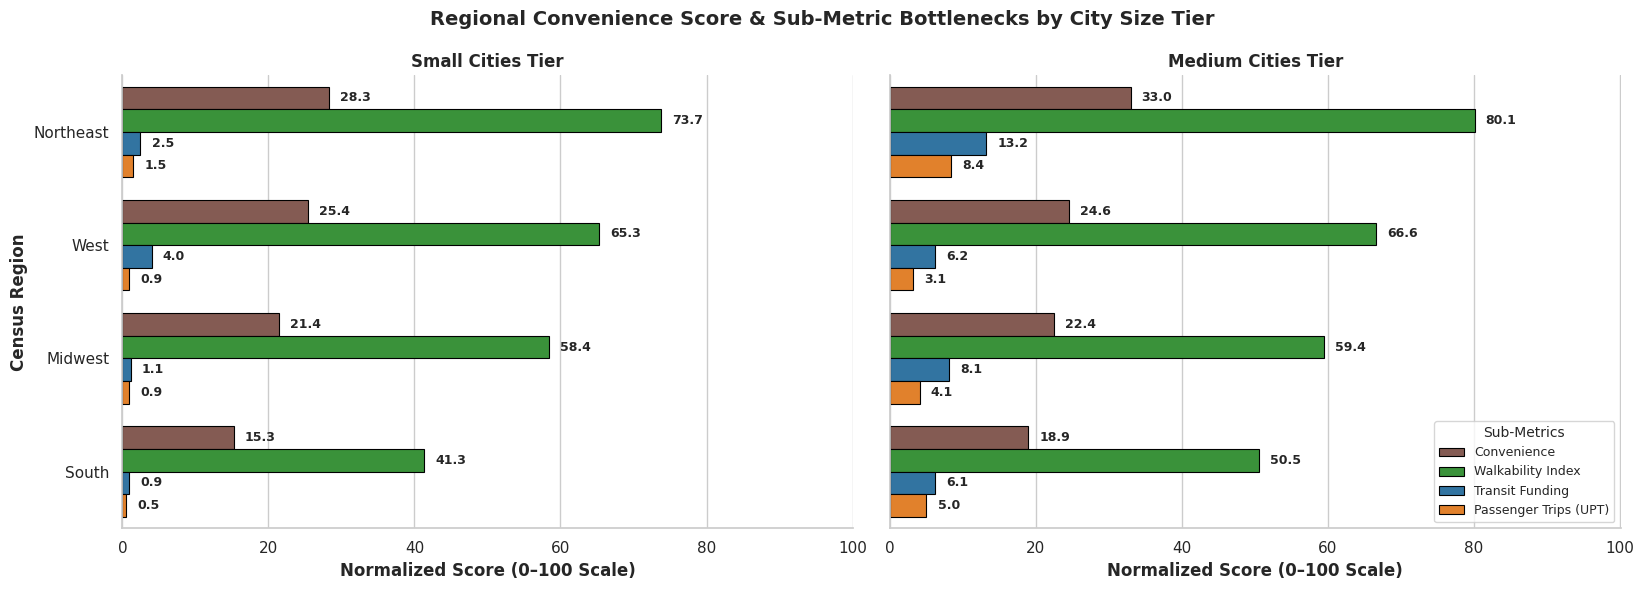

In [ ]:
df_q15 = con_score.copy()

# Filter target years and city size tiers
df_q15 = df_q15[(df_q15['Year'].astype(str).isin(['2020', '2021', '2022', '2023']))
    & (df_q15['Size Tier'].isin(['Small', 'Medium']))].copy()

walk_col = 'avg_walkability'
funding_col = 'Funding'
upt_col = 'ridership'
convenience_col = 'Convenience_Score_100'

# Convert numeric data types
for col in [walk_col, funding_col, upt_col]:
  df_q15[col] = pd.to_numeric(df_q15[col], errors = 'coerce')


# Normalize other factors to 0 - 100 scale
def min_max_scale(series):
  s_min, s_max = series.min(), series.max()
  if s_max == s_min:
    return series * 0
  return ((series - s_min) / (s_max - s_min)) * 100

df_q15['Norm_Walkability'] = min_max_scale(df_q15[walk_col])
df_q15['Norm_Funding'] = min_max_scale(df_q15[funding_col])
df_q15['Norm_UPT'] = min_max_scale(df_q15[upt_col])


grouped = (
    df_q15.groupby(['Size Tier', 'Region'])[
        [
            convenience_col,
            'Norm_Walkability',
            'Norm_Funding',
            'Norm_UPT',
        ]
    ]
    .mean()
    .reset_index()
)

# Melt into long format for visualization
df_plot = grouped.melt(
    id_vars = ['Size Tier', 'Region'],
    value_vars = [
        convenience_col,
        'Norm_Walkability',
        'Norm_Funding',
        'Norm_UPT',
    ],
    var_name = 'Metric',
    value_name = 'Normalized_Score',
)

# Create and map labels
metric_labels = {
    convenience_col: 'Convenience',
    'Norm_Walkability': 'Walkability Index',
    'Norm_Funding': 'Transit Funding',
    'Norm_UPT': 'Passenger Trips (UPT)',
}
df_plot['Metric'] = df_plot['Metric'].map(metric_labels)

# create facets and coloring for sub-metric factors
sns.set_theme(style = 'whitegrid', font = 'sans-serif')

palette = {
    'Convenience': '#8c564b',
    'Walkability Index': '#2ca02c',
    'Transit Funding': '#1f77b4',
    'Passenger Trips (UPT)': '#ff7f0e',
}

# Define explicit region order for the y-axis (top to bottom)
region_order = ['Northeast', 'West', 'Midwest', 'South']

g = sns.catplot(
    data = df_plot,
    kind = 'bar',
    y = 'Region',
    x = 'Normalized_Score',
    hue = 'Metric',
    order = region_order,
    col = 'Size Tier',
    col_order = ['Small', 'Medium'],
    hue_order = [
        'Convenience',
        'Walkability Index',
        'Transit Funding',
        'Passenger Trips (UPT)',
    ],
    palette = palette,
    height = 6,
    aspect = 1.2,
    edgecolor = 'black',
    linewidth = 0.8,
    sharex = True,
)

# Remove hard coded legend
if g._legend:
  g._legend.remove()

# Annotate exact data value to each bar
for ax in g.axes.flat:
  for p in ax.patches:
    width = p.get_width()

    # Ensure data exists before annotating
    if width > 0 and not np.isnan(width):
      ax.annotate(
          f'{width:.1f}',
          (width, p.get_y() + p.get_height() / 2.0),
          ha = 'left',
          va = 'center',
          xytext = (8, 0),
          textcoords = 'offset points',
          fontsize = 9,
          fontweight = 'bold',
      )

g.fig.subplots_adjust(top = 0.82)
g.fig.suptitle(
    'Regional Convenience Score & Sub-Metric Bottlenecks by City'
    ' Size Tier',
    fontsize = 14,
    fontweight = 'bold'
)

g.set_axis_labels(
    'Normalized Score (0–100 Scale)', 'Census Region', fontsize = 12, fontweight = 'bold'
)
g.set_titles(col_template='{col_name} Cities Tier', fontsize=12, weight='bold')

# Edit x axis for visual clarity
max_val = df_plot['Normalized_Score'].max()
for ax in g.axes.flat:
  ax.set_xlim(0, max_val * 1.25 if max_val > 0 else 100)

# Establish legend
plt.legend(title = 'Sub-Metrics', title_fontsize = '10', fontsize = '9', loc = 'lower right')
plt.tight_layout()
plt.show()

# **Conclusion**

This project examined how population growth affects transportation convenience in major U.S. cities from 2020 to 2023. By combining population, public transit funding, ridership, and walkability data, we developed a Transportation Convenience Score to compare cities across different population tiers. Our analysis found that transportation convenience varies across cities, suggesting that population size alone does not determine how accessible and convenient a city's transportation system is.

One of our key findings was that population growth had almost no relationship with changes in transportation convenience. The correlation between population growth and percentage change in convenience was approximately **0.03**, indicating virtually no linear relationship. Similarly, changes in walkability, funding, and ridership scores had very weak relationships with population growth. Although transit ridership increased across all population tiers between 2020 and 2023, the rate of increase differed by tier, with large cities experiencing the greatest increase. These results suggest that growing cities do not necessarily experience greater improvements in transportation convenience, and population growth alone is not a reliable indicator of transit performance.

These findings are important for students and recent graduates deciding where to live for school or employment, particularly those who want to avoid the cost of owning a car. Rather than assuming that larger or faster-growing cities offer better transportation, individuals should compare multiple factors, including transit usage, public funding, and walkability, when evaluating potential destinations. For city planners, the results also highlight the importance of evaluating transportation outcomes rather than relying on population growth alone. While our Convenience Score provides a useful starting point for comparing cities, it is a simplified measure and does not capture every aspect of accessibility or affordability. Future analysis could incorporate commute times, transit service frequency, and fare costs to provide a more complete picture of transportation convenience.

## **Challenges With Data**

We synthesized multi-source public datasets across transit, walkability, and demographic domains, which presented two primary analytical challenges:

- Multi-Scale Geographic Harmonization:
Our source data spanned four distinct administrative boundaries: Census incorporated cities, transit agency headquarters, Census Urbanized Areas (UACE), and EPA block groups. To align these incompatible spatial granularities, we wrote automated string-standardization functions to normalize geographic names across disparate sources, and performed GIS spatial joins to aggregate block-group walkability to the city level. For UACE-level ridership and funding data, we mapped regional transit footprints to corresponding core cities to maintain data integrity.

- Temporal Alignment & External Noise (2020–2023):
Matching disparate data availability required constraining our panel dataset to a synchronized 2020–2023 window. This timeframe captures extreme external shocks, specifically the sharp post-2020 pandemic decline and subsequent ridership recovery, requiring careful interpretation of baseline mobility trends.


## **Risks and Limitations**

## Risks

- Geographic Mismatch: Population data is reported at the city level, while transportation data may use urbanized areas or transit agency boundaries, potentially affecting comparisons.
- External Factors: COVID-19, changes in commuting patterns, and shifts in transportation policy or funding may influence transit usage independently of population growth.
- Correlation vs. Causation: Population growth may be associated with transportation convenience without directly causing improvements in transit availability or usage.

## Limitations

- Data Availability and Consistency: Differences in reporting periods, missing observations, and inconsistent definitions across datasets may limit the accuracy of comparisons between cities.
- Simplified Convenience Measure: Combining transit usage, vehicle revenue miles, walkability, and funding into a single score requires assigning weights that may not fully capture transportation convenience.
- Funding Does Not Equal Service Quality: Higher transportation funding does not necessarily translate into better accessibility, service frequency, or passenger experience.
- Limited Analytical Scope: Other factors, such as income, population density, car ownership, and land-use patterns, may also influence transportation convenience but are not fully captured in our analysis.

## **Next Steps & Future Considerations**

This project's thorough analysis of 2020-2025 Census, Ridership, UPT, State Funding, and City/Town datasets provides a solid foundation for future feature additions and machine learning applications including XGBoost and Random Forest Regressor to create a national index that supports students and job seekers in the US. In practice, the results of this analysis can help potential internationals and domestics find areas suitable for study, leisure, and work. Data scraping automation methods can fundamentally improve the process of this analysis report for current and future applications in real-time reporting.
<br>
<br>
Despite the potential of this analysis, there are several existing limitations.
Many of the datasets had varying degrees of utilization, where most were incomplete and inconsistent, or had many irrelevant datapoints that were difficult to sift through. Performing this analysis required dropping many datapoints to be able to get a cleaned and usable dataset to perform analysis on. Future real-time reporting will require the use of machine learning regression analysis in combination with assessing current domestic events such as illnesses and health cycles, transportation system innovation, policymaking, and urban planning before making accurate statements about convenience scoring and indexing. Without considering these factors, the convenience index lacks credibility and should only be used as reference over fact.
<br>
<br>
Moving ahead, this analysis can be used by students as they transition into their professional careers. Beyond academic applications, this model can be improved further by integrating different datasets including transportation modes, fares, travel time, backlog frequency, weather and seasonality, rideshare logs, congestion, road conditions, and similar datasets. Including current events and holistic comprehensive data will provide not just students and working class, but also policymakers, local governments, and urban planners the areas of improvement opportunities to bolster their local convenience score, in addition to other world known indices like happiness. With the addition of automated data scraping pipelines by connecting to national and regional databases like census, ridership, and funding, future iterations of this project can improve data collection and study methods, and can serve as a tool in transportation systems analysis for how  convenience can impact and enact how quality of life is perceived in US cities.

# **References**

[2000-2010 Census Data](https://www.census.gov/data/datasets/time-series/demo/popest/intercensal-2000-2010-cities-and-towns.html)
<br>
[2010-2020 Census Data](https://www.census.gov/data/tables/time-series/demo/popest/intercensal-2010-2020-cities.html)
<br>
[2020-2025 Census Data](https://www.census.gov/data/tables/time-series/demo/popest/2020s-total-cities-and-towns.html)
<br>
[2010 Census Demographic Data](https://www.census.gov/geographies/mapping-files/2010/geo/tiger-data.html)
<br>
[Funding Data](https://www.transit.dot.gov/ntd/data-product/ts11-total-funding-time-series-2)
<br>
[Ridership Data](https://www.transit.dot.gov/ntd/data-product/monthly-module-raw-data-release)
<br>
[National Walkability Index](https://zenodo.org/records/20545549)
<br>
[Social Data Commons Walkability](https://doi.org/10.5281/zenodo.20545549)
<br>
[EPA Location Data](https://www.epa.gov/smartgrowth/smart-location-mapping)
<br>
[Google Gemini](https://gemini.google.com/) ==> Debugging, Coding Clarity, Wording Assistance, Ideation & Brainstorming
<br>
[ChatGPT](https://https://chatgpt.com/) ==> Subject Clarification & Word Refinement
<br>
[Former Projects](https://github.com/soltaniehha/Intro-to-Data-Analytics/blob/main/docs/team-projects/2025/A10-Time-Series-Analysis-of-US-Treasury-Yields-and-Equity-Markets-for-Improved-Forecasting.ipynb) ==> Formatting Referencing & Question Generation Inspiration

# **Generative AI Disclosure**

We used several Generative AI tools to assist in idea generation, code assistance, and word phrasing. All data, visuals, and analyses come from our sources and notebook directly, and are in no way affected by Generative AI.

**Tools used:**
* **Google Gemini:** Main AI source of coding assistance, idea generation, phrasing refinement, and brainstorming collaborator
* **ChatGPT:** Used mainly for subject clarification, word refinement, and workflow visualization

**What AI did not do:**
* Fabricate Data, Generate Insights & Analyses
* We reviewed each suggestion for relevance and clarity, keeping only those enhancing our research and analysis
* No private or sensitive data was shared with these tools during the process of this project

**Reproducibility:**

* Data: US Census, NTD Funding, Ridership, Walkability, EPA.
* Libraries: pandas, numpy, matplotlib, csv, geopandas, regular expressions, seaborn.
* Re-running the notebook on these files will recreate the exact figures and metrics returned.

**Summary: AI assisted in brainstorming & planning, coding assistance, and wording refinement**